# Beat response times

Observed CAD timings by beat, priority and time, Oakland Police Department, Jan 2021 - Jun 2026.

| Measure | Definition | Years |
|---|---|---|
| Wait for dispatch | dispatch - incident created | 2021-2026 |
| Dispatch to arrival | first unit arrived - dispatched | 2021-2026 |
| Response time | first unit arrived - incident created | 2021-2026 |
| Travel time | first unit arrived - en route | 2026 only (the only year with an en-route timestamp) |

"Incident created" is `CREATE TIME INCIDENT` (2021-23), `I_tTimeCreate` (2024) and `InsertedTimestamp` (2025-26), treated as the same event.

**Calls kept:** public calls (911, phone, text) at priority 0-3 that involve police. Removed:
- ambulance-only requests, dispatcher broadcasts and misdials;
- April-May 2026, where officer timestamps are misaligned in the source export;
- rows dispatched before the incident was created, or arriving before dispatch.

Dispatch to arrival and travel time are kept only between 0.5 and 60 minutes, and wait and response only up to 24 hours. 8 minutes is a peer benchmark, not an OPD standard.

Maps shade each beat by its median. Each map splits its beats into seven equal-sized colour groups, green (shortest) to red (longest), with its own legend.

In [1]:
import textwrap

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap
from scipy.ndimage import gaussian_filter1d
from box_utils import BOX_ROOT

DATA = BOX_ROOT / "OPD & TAN - Core Workspace" / "02 Oakland Police Dept (OPD)" / "Data" / "Our Data"

PUBLIC_SOURCES = {"911", "911 CALL", "PHONE", "DEFAULT - PHONE INIT", "TEXT"}
NON_POLICE_TYPES = ("AMBULANCE REQ", "BEAT INFO", "MISDIAL")
PRIORITIES = [0, 1, 2, 3]
BAD_EXPORT = ("2026-04-01", "2026-06-01")      # officer timestamps misaligned in the source export
SLA = 8                                         # minutes

AREA_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#eda100", 5: "#e87ba4", 6: "#008300"}
PRIORITY_LABELS = {0: "P0 - officer safety or catastrophe", 1: "P1 - imminent danger to persons",
                   2: "P2 - urgent, not an immediate emergency", 3: "P3 - non-emergency, no cover needed"}
PRIORITY_COLORS = {0: "#8f1d4a", 1: "#d62728", 2: "#f28e2b", 3: "#2f6db3"}     # warm = urgent, cool = not
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e6e3"
HALO = [pe.withStroke(linewidth=2.5, foreground="white")]

# map colours: 7 classes per map, each holding about the same number of beats; green = shortest, red = longest
MAP_CLASSES = 7
MAP_COLORS = LinearSegmentedColormap.from_list("minutes", ["#006d2c", "#74c476", "#ffd600", "#f77f00", "#c1121f"], N=MAP_CLASSES)

In [2]:
# Geography: beats, Patrol Areas, police facilities.
beats = gpd.read_file("https://data.oaklandca.gov/api/geospatial/78s7-673i?method=export&format=GeoJSON")
beats = (beats[["name", "pol_dist", "geometry"]].rename(columns={"name": "beat", "pol_dist": "area"})
               .query("beat not in ['LKM1', 'PDT2']").sort_values("beat").reset_index(drop=True))
beats["area"] = beats["area"].astype(int)
beats["geometry"] = beats.geometry.apply(lambda g: max(g.geoms, key=lambda p: p.area) if g.geom_type == "MultiPolygon" else g)
utm = beats.to_crs(26910).geometry
cen = utm.centroid
cen[~cen.within(utm)] = utm.representative_point()[~cen.within(utm)]
beats["center_lon"], beats["center_lat"] = cen.to_crs(4326).x, cen.to_crs(4326).y

# Patrol Area outlines; grow 1 m, dissolve, shrink 1 m to close sub-metre gaps between beat polygons
areas = (beats[["area", "geometry"]].to_crs(26910).assign(geometry=lambda d: d.buffer(1))
         .dissolve(by="area").assign(geometry=lambda d: d.buffer(-1)).to_crs(4326).reset_index())

facilities = pd.DataFrame([{"facility": "PAB", "lon": -122.27475, "lat": 37.79948},         # Police Administration Building
                           {"facility": "Eastmont", "lon": -122.17545, "lat": 37.76752}])   # Eastmont substation

print(f"{len(beats)} beats | {len(areas)} Patrol Areas")


57 beats | 6 Patrol Areas


In [3]:
# Calls, 2021-2026: apply the cleaning rules in order and log what each removes.
raw = pd.read_parquet(DATA / "harmonized_calls_2021_2026.parquet",
                      columns=["event_number", "beat", "call_source", "priority", "event_time",
                               "dispatch_time", "arrival_time", "incident_type_desc"])
raw["priority"] = pd.to_numeric(raw["priority"], errors="coerce")
itype = raw["incident_type_desc"].fillna("").str.upper()
rules = {
    "public call (911, phone, text)": raw["call_source"].str.upper().isin(PUBLIC_SOURCES),
    "priority 0-3": raw["priority"].isin(PRIORITIES),
    "police involved": ~itype.str.startswith(NON_POLICE_TYPES),
    "outside Apr-May 2026": ~raw["event_time"].between(*BAD_EXPORT, inclusive="left"),
    "not dispatched before created": ~(raw["dispatch_time"] < raw["event_time"]),
    "not arrived before dispatch": ~(raw["arrival_time"] < raw["dispatch_time"]),
}
keep = pd.Series(True, index=raw.index)
log = [("all CAD rows", len(raw))]
for name, mask in rules.items():
    keep &= mask
    log.append((name, int(keep.sum())))

calls = raw[keep].merge(beats[["beat", "area"]], on="beat")                 # 57 OPD beats only
log.append(("in an OPD beat", len(calls)))
calls["priority"] = calls["priority"].astype(int)

def minutes(end, start):
    return (calls[end] - calls[start]).dt.total_seconds() / 60

calls["dispatch_arrival_min"] = minutes("arrival_time", "dispatch_time").where(lambda s: s.between(0.5, 60))
calls["wait_min"] = minutes("dispatch_time", "event_time").where(lambda s: s <= 1440)
calls["response_min"] = minutes("arrival_time", "event_time").where(lambda s: s <= 1440).where(calls["dispatch_arrival_min"].notna())
calls["hour"] = calls["event_time"].dt.hour
calls["year"] = calls["event_time"].dt.year
calls["month"] = calls["event_time"].dt.strftime("%Y-%m")

print(pd.DataFrame(log, columns=["rule", "rows kept"]).to_string(index=False))
print(f"\n{calls['dispatch_arrival_min'].notna().sum():,} with dispatch to arrival | {calls['wait_min'].notna().sum():,} with a wait")

                          rule  rows kept
                  all CAD rows    2276366
public call (911, phone, text)    1820266
                  priority 0-3    1655426
               police involved    1405074
          outside Apr-May 2026    1363219
 not dispatched before created    1363196
   not arrived before dispatch    1355077
                in an OPD beat    1336120

498,582 with dispatch to arrival | 651,717 with a wait


In [4]:
# 2026 travel time: en-route time exists only in the raw 2026 sheet; join it to the cleaned calls by incident number.
#   Kept when the unit assigned first is the unit that arrived, so en route and arrival belong to the same car.
enroute = pd.read_excel(DATA / "2021-2026current.xlsx", sheet_name="2026 ",
                        usecols=["IncidentNumber", "FirstUnitEnrouteTime", "FirstUnitAssignmentTime", "FirstUnitAssignmentWithArrivalTime"])
enroute = enroute.drop_duplicates("IncidentNumber", keep=False).rename(columns={"IncidentNumber": "event_number"})
calls = calls.merge(enroute, on="event_number", how="left", validate="many_to_one")

same_unit = calls["FirstUnitAssignmentWithArrivalTime"] == calls["FirstUnitAssignmentTime"]
calls["travel_min"] = minutes("arrival_time", "FirstUnitEnrouteTime").where(lambda s: s.between(0.5, 60) & same_unit & (calls["year"] == 2026))
calls["dispatch_enroute_min"] = minutes("FirstUnitEnrouteTime", "dispatch_time").where(lambda s: s.between(0, 60))
travel = calls[calls["travel_min"].notna()].copy()
print(f"{len(travel):,} calls with a 2026 travel time ({travel['month'].min()} to {travel['month'].max()}, Apr-May excluded)")

25,690 calls with a 2026 travel time (2026-01 to 2026-06, Apr-May excluded)


In [5]:
# Median minutes per stage, by priority.
STAGES = {"wait_min": "wait for dispatch", "dispatch_arrival_min": "dispatch to arrival", "response_min": "response time",
          "dispatch_enroute_min": "dispatch to en route (2026)", "travel_min": "travel time (2026)"}
stage_medians = calls.groupby("priority")[list(STAGES)].median().rename(columns=STAGES).round(1)
stage_counts = calls.groupby("priority")[list(STAGES)].count().rename(columns=STAGES)
display(stage_medians.rename(index=PRIORITY_LABELS))
display(stage_counts.rename(index=PRIORITY_LABELS))

# wait for dispatch and response time by year
for col in ("wait_min", "response_min"):
    display(calls.pivot_table(index="year", columns="priority", values=col, aggfunc="median").round(1)
                 .rename(columns=PRIORITY_LABELS).rename_axis(columns=f"median {STAGES[col]}, minutes"))

,wait for dispatch,dispatch to arrival,response time,dispatch to en route (2026),travel time (2026)
priority,,,,,
P0 - officer safety or catastrophe,1.5,5.9,9.9,NaN,37.4
P1 - imminent danger to persons,2.1,7.0,11.1,0.2,6.7
"P2 - urgent, not an immediate emergency",119.9,8.8,122.5,0.1,8.5
"P3 - non-emergency, no cover needed",260.0,10.2,258.2,0.1,10.4


,wait for dispatch,dispatch to arrival,response time,dispatch to en route (2026),travel time (2026)
priority,,,,,
P0 - officer safety or catastrophe,64,55,55,0,1
P1 - imminent danger to persons,215259,185634,185435,10952,8945
"P2 - urgent, not an immediate emergency",365148,259394,248158,21364,13519
"P3 - non-emergency, no cover needed",71246,53499,45235,5156,3225


"median wait for dispatch, minutes",P0 - officer safety or catastrophe,P1 - imminent danger to persons,"P2 - urgent, not an immediate emergency","P3 - non-emergency, no cover needed"
year,,,,
2021,1.2,2.0,99.6,248.5
2022,1.1,2.4,115.5,255.8
2023,1.6,1.5,221.7,414.3
2024,1.7,2.5,121.4,243.1
2025,1.3,2.1,107.2,215.2
2026,21.9,1.8,115.3,239.3


"median response time, minutes",P0 - officer safety or catastrophe,P1 - imminent danger to persons,"P2 - urgent, not an immediate emergency","P3 - non-emergency, no cover needed"
year,,,,
2021,12.1,10.7,103.4,244.6
2022,6.5,11.4,119.9,245.6
2023,16.2,10.8,227.1,420.9
2024,6.8,11.2,122.8,245.8
2025,10.0,11.0,108.4,210.8
2026,27.2,11.0,114.9,234.2


## Plot helpers

In [6]:
# Map helpers. Each takes a calls table and the name of a minutes column.
def map_scale(values):
    """quantile class edges in minutes, rounded"""
    q = np.nanquantile(values, np.linspace(0, 1, MAP_CLASSES + 1))
    edges = np.unique([round(x, 1) if x < 10 else round(x) for x in q])
    return BoundaryNorm(edges, MAP_COLORS.N, clip=True), edges

def minutes_label(m):
    return f"{m:.1f}" if m < 20 else f"{m:.0f}"

def colorbar(ax, scale, label):
    norm, edges = scale
    plt.colorbar(plt.cm.ScalarMappable(cmap=MAP_COLORS, norm=norm), ax=ax, shrink=.55, pad=.01, fraction=.04,
                 ticks=edges, spacing="uniform", format="%g", label=label)

MIN_CALLS = 10                                          # beats with fewer calls on a map are left white

def beat_choropleth(ax, df, col, label_size=6, show_n=False):
    """beats shaded by median minutes, colour classes fitted to this map; returns the per-beat table"""
    by_beat = df.groupby("beat")[col].agg(n="count", median="median")
    by_beat = by_beat[by_beat["n"] >= MIN_CALLS]
    shaded = beats.merge(by_beat, left_on="beat", right_index=True, how="left")
    scale = map_scale(by_beat["median"])
    shaded.plot(ax=ax, column="median", cmap=MAP_COLORS, norm=scale[0], edgecolor="#7a7a75", linewidth=.6, missing_kwds={"color": "white"})
    areas.boundary.plot(ax=ax, color=INK, linewidth=1.8, zorder=4)
    for b in shaded.itertuples():
        text = b.beat if pd.isna(b.median) else f"{b.beat}\n{minutes_label(b.median)}" + (f" (n={b.n:,.0f})" if show_n else "")
        ax.annotate(text, (b.center_lon, b.center_lat), ha="center", va="center", fontsize=label_size, path_effects=HALO, zorder=5)
    for a in areas.itertuples():
        pt = a.geometry.representative_point()
        ax.annotate(f"Area {a.area}", (pt.x, pt.y), xytext=(0, -14), textcoords="offset points", ha="center",
                    fontsize=label_size + 3, fontweight="bold", path_effects=HALO, zorder=6)
    for f in facilities.itertuples():
        ax.scatter(f.lon, f.lat, marker="*", s=200, color="#0072b2", edgecolor="white", linewidth=.8, zorder=6)
        ax.annotate(f.facility, (f.lon, f.lat), xytext=(6, 5), textcoords="offset points", fontsize=label_size + 2, fontweight="bold",
                    path_effects=HALO, zorder=6)
    colorbar(ax, scale, "median minutes per beat")
    x0, y0, x1, y1 = beats.total_bounds
    ax.set_xlim(x0 - .003, x1 + .003); ax.set_ylim(y0 - .003, y1 + .003)
    ax.set_aspect(1 / np.cos(np.radians(37.8)))
    ax.set_axis_off()
    return by_beat

def beat_maps(groups, col, suptitle, ncols=2):
    """one beat map per (title, calls) group; groups with no beat reaching MIN_CALLS are skipped"""
    groups = [(t, df) for t, df in groups if (df.groupby("beat")[col].count() >= MIN_CALLS).any()]
    nrows = -(-len(groups) // ncols)
    x0, y0, x1, y1 = beats.total_bounds
    map_h = 9                                                    # inches per map; width follows the city's shape
    map_w = map_h * (x1 - x0) * np.cos(np.radians(37.8)) / (y1 - y0) + 1.3     # + colour bar
    fig, axes = plt.subplots(nrows, ncols, figsize=(map_w * ncols, (map_h + .6) * nrows), squeeze=False, layout="constrained")
    fig.get_layout_engine().set(w_pad=.02, h_pad=.04, wspace=.01, hspace=.02)
    for ax, (title, df) in zip(axes.flat, groups):
        beat_choropleth(ax, df, col)
        ax.set_title(f"{title}\n{df[col].count():,} calls | median {df[col].median():.1f} min", loc="left", fontsize=10)
    for ax in axes.flat[len(groups):]:
        ax.set_axis_off()
    fig.suptitle(suptitle, x=.01, ha="left")
    plt.show()

def beat_map(df, col, title):
    """single large beat map with call counts"""
    fig, ax = plt.subplots(figsize=(11, 11), layout="constrained")
    by_beat = beat_choropleth(ax, df, col, label_size=6, show_n=True)
    ax.legend(handles=[plt.Line2D([], [], marker="*", ls="", ms=14, color="#0072b2", mec="white",
                                  label="police facility (PAB = Police Administration Building; Eastmont substation)"),
                       plt.Line2D([], [], color=INK, lw=1.8, label="Patrol Area boundary")],
              loc="lower left", frameon=False, fontsize=8.5)
    ax.set_title(f"{title}: median minutes per beat", loc="left")
    plt.show()
    return by_beat.sort_values("median", ascending=False).round(1)

TIME_BANDS = {"late night 23-05": [23, 0, 1, 2, 3, 4, 5], "morning 06-11": range(6, 12),
              "afternoon 12-17": range(12, 18), "evening 18-22": range(18, 23)}

def slice_maps(df, col, label):
    """priority and time-of-day slices, hour-of-day line, then the per-beat map"""
    d = df.dropna(subset=[col])
    beat_maps([(PRIORITY_LABELS[p], d[d["priority"] == p]) for p in PRIORITIES], col, f"{label}: by priority")
    beat_maps([(t, d[d["hour"].isin(h)]) for t, h in TIME_BANDS.items()], col, f"{label}: by time of day")

    by_hour = d.groupby("hour")[col].agg(median="median", p75=lambda s: s.quantile(.75))
    fig, ax = plt.subplots(figsize=(10, 3.5))
    for h in (6, 14, 21):                                     # shift changes
        ax.axvspan(h, h + 1, color=GRID, label="shift change" if h == 6 else None)
    ax.plot(by_hour.index, by_hour["median"], color="#238b45", linewidth=2, label="median")
    ax.plot(by_hour.index, by_hour["p75"], color="#9a9a94", linewidth=1.2, linestyle="--", label="p75")
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour call received"); ax.set_ylabel("minutes"); ax.set_ylim(0)
    ax.set_title(f"{label}: by hour of day", loc="left"); ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color=GRID, linewidth=.6); ax.set_axisbelow(True)
    plt.show()

    display(beat_map(d, col, label).head(10))

In [7]:
# Distribution curves: smoothed histograms, one line per Patrol Area (plus citywide) or per priority; the y-axis is
#   % of the group's calls in each bin. Short measures: 0.5-min bins to 60 min. Response time: 5-min bins to 24 h.
PRIORITY_NOTE = ("OPD priority codes: P0 reserved for officer safety and natural or man-made catastrophes. P1 imminent potential for serious "
                 "injury to persons, violent crimes, serious public hazards, felonies in progress; any officer citywide can be sent. P2 urgent, "
                 "but not an immediate emergency; sent from the call's Patrol Area. P3 no cover needed, cold reports, non-emergencies. "
                 "Source: PFM staffing study (Dec 2024) p.101; CPSM (Dec 2020) p.56.")

def curve(x, edges):
    counts, _ = np.histogram(x, bins=edges)
    return gaussian_filter1d(counts / counts.sum() * 100, sigma=2, mode="constant")

def distribution(df, col, by, title, xlabel, caption, max_min=60, bin_min=.5, xlim=45, log=False):
    """one curve per Patrol Area (by="area") or per priority (by="priority"); groups with fewer than 20 calls are listed, not drawn"""
    d = df.dropna(subset=[col])
    edges = np.geomspace(1, max_min, 65) if log else np.arange(0, max_min + bin_min, bin_min)   # log: ~20 bins per decade
    mids = np.sqrt(edges[:-1] * edges[1:]) if log else edges[:-1] + bin_min / 2
    stats = d.groupby(by)[col].agg(n="size", median="median", within_8=lambda s: (s <= SLA).mean() * 100)
    if by == "area":
        keys, colors, names = sorted(stats.index), AREA_COLORS, {a: f"Area {a}" for a in stats.index}
    else:
        stats = stats.reindex(PRIORITIES).fillna({"n": 0})
        keys, colors, names = PRIORITIES, PRIORITY_COLORS, PRIORITY_LABELS
    drawn = [k for k in keys if stats.loc[k, "n"] >= 20]
    curves = {k: curve(d.loc[d[by] == k, col], edges) for k in drawn}
    if by == "area":
        curves["citywide"] = curve(d[col], edges)
    y_top = max(c.max() for c in curves.values())

    fig, ax = plt.subplots(figsize=(13, 7.4))
    handles, medians = [], []
    for k in drawn:
        ax.plot(mids, curves[k], color=colors[k], lw=2.2, zorder=3)
        s = stats.loc[k]
        handles.append(plt.Line2D([], [], color=colors[k], lw=2.2,
                                  label=f"{names[k]}  |  {s['within_8']:.0f}% within {SLA}  |  n = {s['n']:,.0f}"))
        medians.append((s["median"], names[k].split(" - ")[0], colors[k]))
    if by == "area":
        ax.plot(mids, curves["citywide"], color=INK, lw=2.8, zorder=5, path_effects=[pe.Stroke(linewidth=4.8, foreground="white"), pe.Normal()])
        handles.append(plt.Line2D([], [], color=INK, lw=2.8,
                                  label=f"citywide  |  {(d[col] <= SLA).mean() * 100:.0f}% within {SLA}  |  n = {len(d):,}"))
        medians.append((d[col].median(), "citywide", INK))
    # median of each curve: dotted vertical line in the curve's colour, value labelled at the top (staggered, smallest first)
    for j, (m, short, color) in enumerate(sorted(medians)):
        ax.axvline(m, color=color, lw=1.4, ls=(0, (1.5, 1.5)), zorder=4)
        ax.annotate(f"{short} median {m:.1f} min" if m < 120 else f"{short} median {m / 60:.1f} h", (m, y_top * (1.25 - .055 * j)),
                    xytext=(3, 0), textcoords="offset points", fontsize=8, color=INK, va="center", path_effects=HALO, zorder=6)
    ax.axvline(SLA, color=INK, lw=1.2, ls=(0, (4, 3)), zorder=2)
    ax.annotate(f"{SLA} min", (SLA, y_top * 1.32), xytext=(3, 0), textcoords="offset points", fontsize=8, color=INK, va="center",
                path_effects=HALO, zorder=6)
    ax.set_xlim(1 if log else 0, xlim)
    if log:                                                     # log axis: ticks at round minute / hour marks
        ticks = [1, 2, 5, 10, 15, 30, 60, 120, 240, 480, 1440]
        ax.set_xscale("log"); ax.set_xticks(ticks, [f"{m} min" if m < 60 else f"{m // 60} h" for m in ticks]); ax.minorticks_off()
    elif xlim > 60:                                               # label long axes in hours
        ax.set_xticks(range(0, xlim + 1, 120), [f"{m // 60} h" for m in range(0, xlim + 1, 120)])
    else:
        ax.set_xticks(range(0, xlim + 1, 5))
    ax.set_ylim(0, y_top * 1.36)
    ax.set_xlabel(xlabel, fontsize=9.5, color=MUTED)
    ax.set_ylabel("% of calls", fontsize=9.5, color=MUTED)
    ax.tick_params(colors=MUTED, labelsize=8.5)
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.grid(color=GRID, lw=.6); ax.set_axisbelow(True)
    ax.legend(handles=handles, loc="upper right", fontsize=9, frameon=False, handlelength=2.6)
    ax.set_title(f"{title}, by {'Patrol Area' if by == 'area' else 'priority'}", loc="left", fontsize=12.5, color=INK, pad=12)
    missing = [f"{names[k]} (n = {int(stats.loc[k, 'n'])})" for k in keys if k not in drawn]
    note = (PRIORITY_NOTE + " " if by == "priority" else "") + caption + (f" Too few calls to draw: {', '.join(missing)}." if missing else "")
    fig.text(.01, .005, textwrap.fill(note, 190, break_on_hyphens=False), fontsize=7.5, color=MUTED, va="bottom", linespacing=1.45)
    fig.tight_layout(rect=(0, .05 + .022 * len(textwrap.wrap(note, 190, break_on_hyphens=False)), 1, 1))
    plt.show()
    return stats.rename(index=names).round(1)

SMOOTHING = "Each curve is a smoothed histogram; y = % of the group's calls in each bin. Public police calls, P0-P3. 8 min is a peer benchmark, not an OPD standard."
TRAVEL_NOTE = ("Travel time = first unit arrived - en route (2026 CAD sheet), kept if 0.5-60 min and the first assigned unit is the unit that "
               "arrived. Apr-May 2026 excluded. 0.5-min bins, x-axis cut at 45 min. " + SMOOTHING)
DISPATCH_NOTE = ("Dispatch to arrival = first unit arrived - dispatched (harmonized CAD table), kept if 0.5-60 min. Apr-May 2026 excluded. "
                 "0.5-min bins, x-axis cut at 45 min. " + SMOOTHING)
RESPONSE_NOTE = ("Response time = first unit arrived - incident created, kept when dispatch to arrival is 0.5-60 min and the total is at most "
                 "24 h. Apr-May 2026 excluded. 5-min bins. " + SMOOTHING)

## Travel time (en route -> arrival), 2026

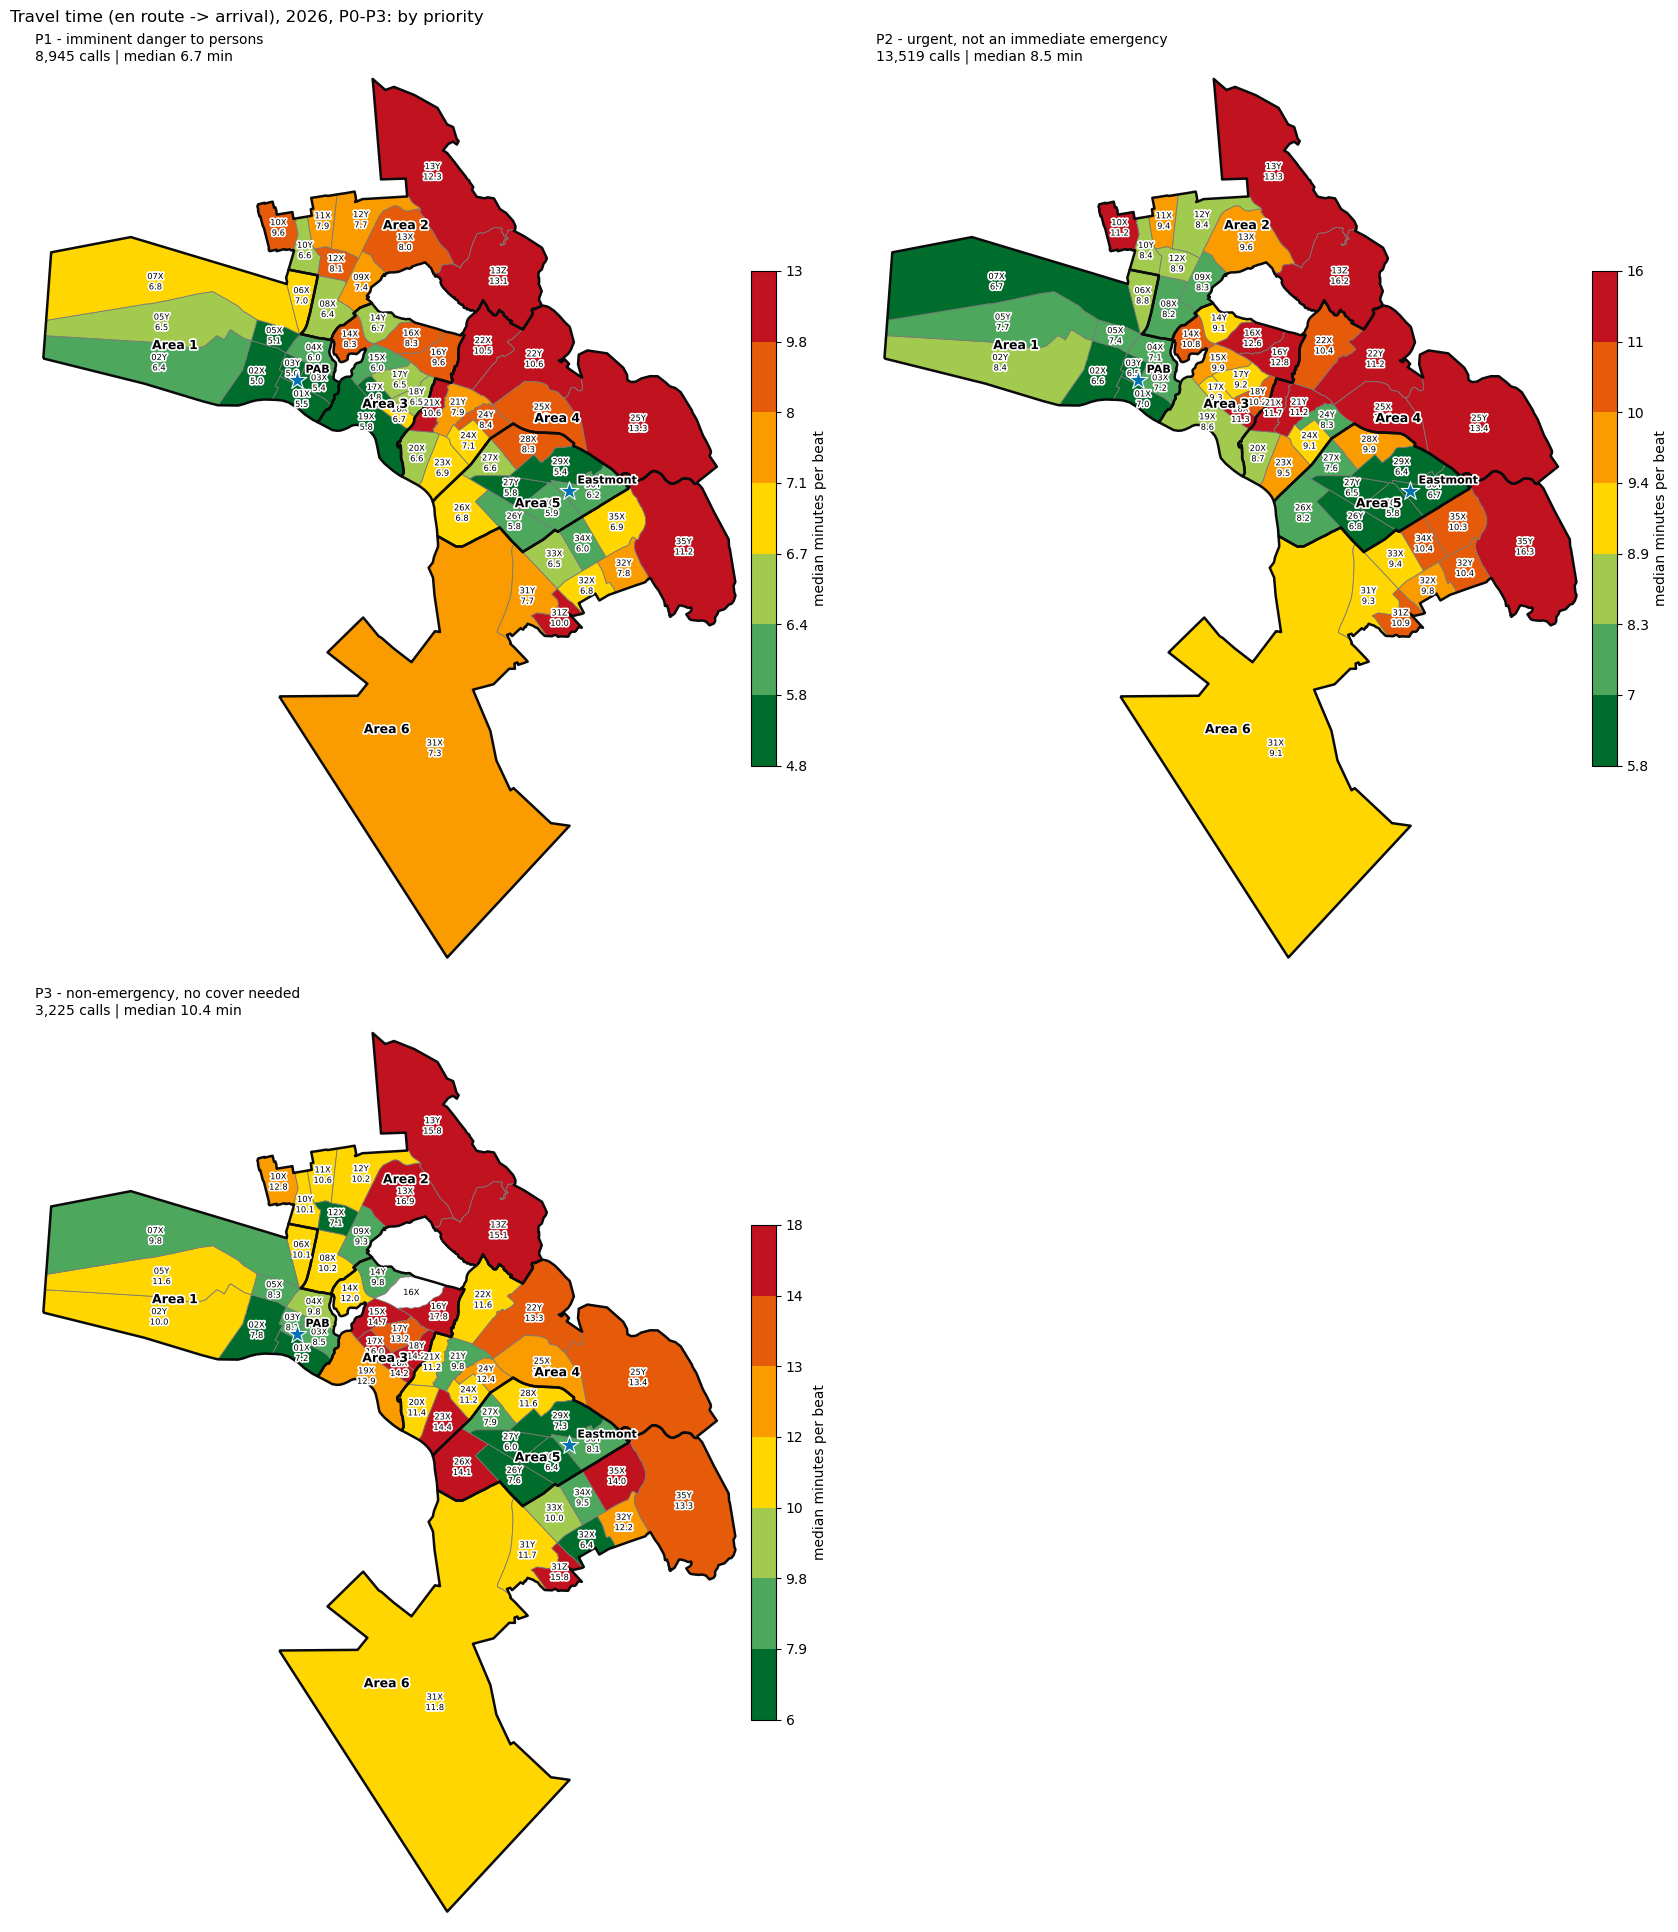

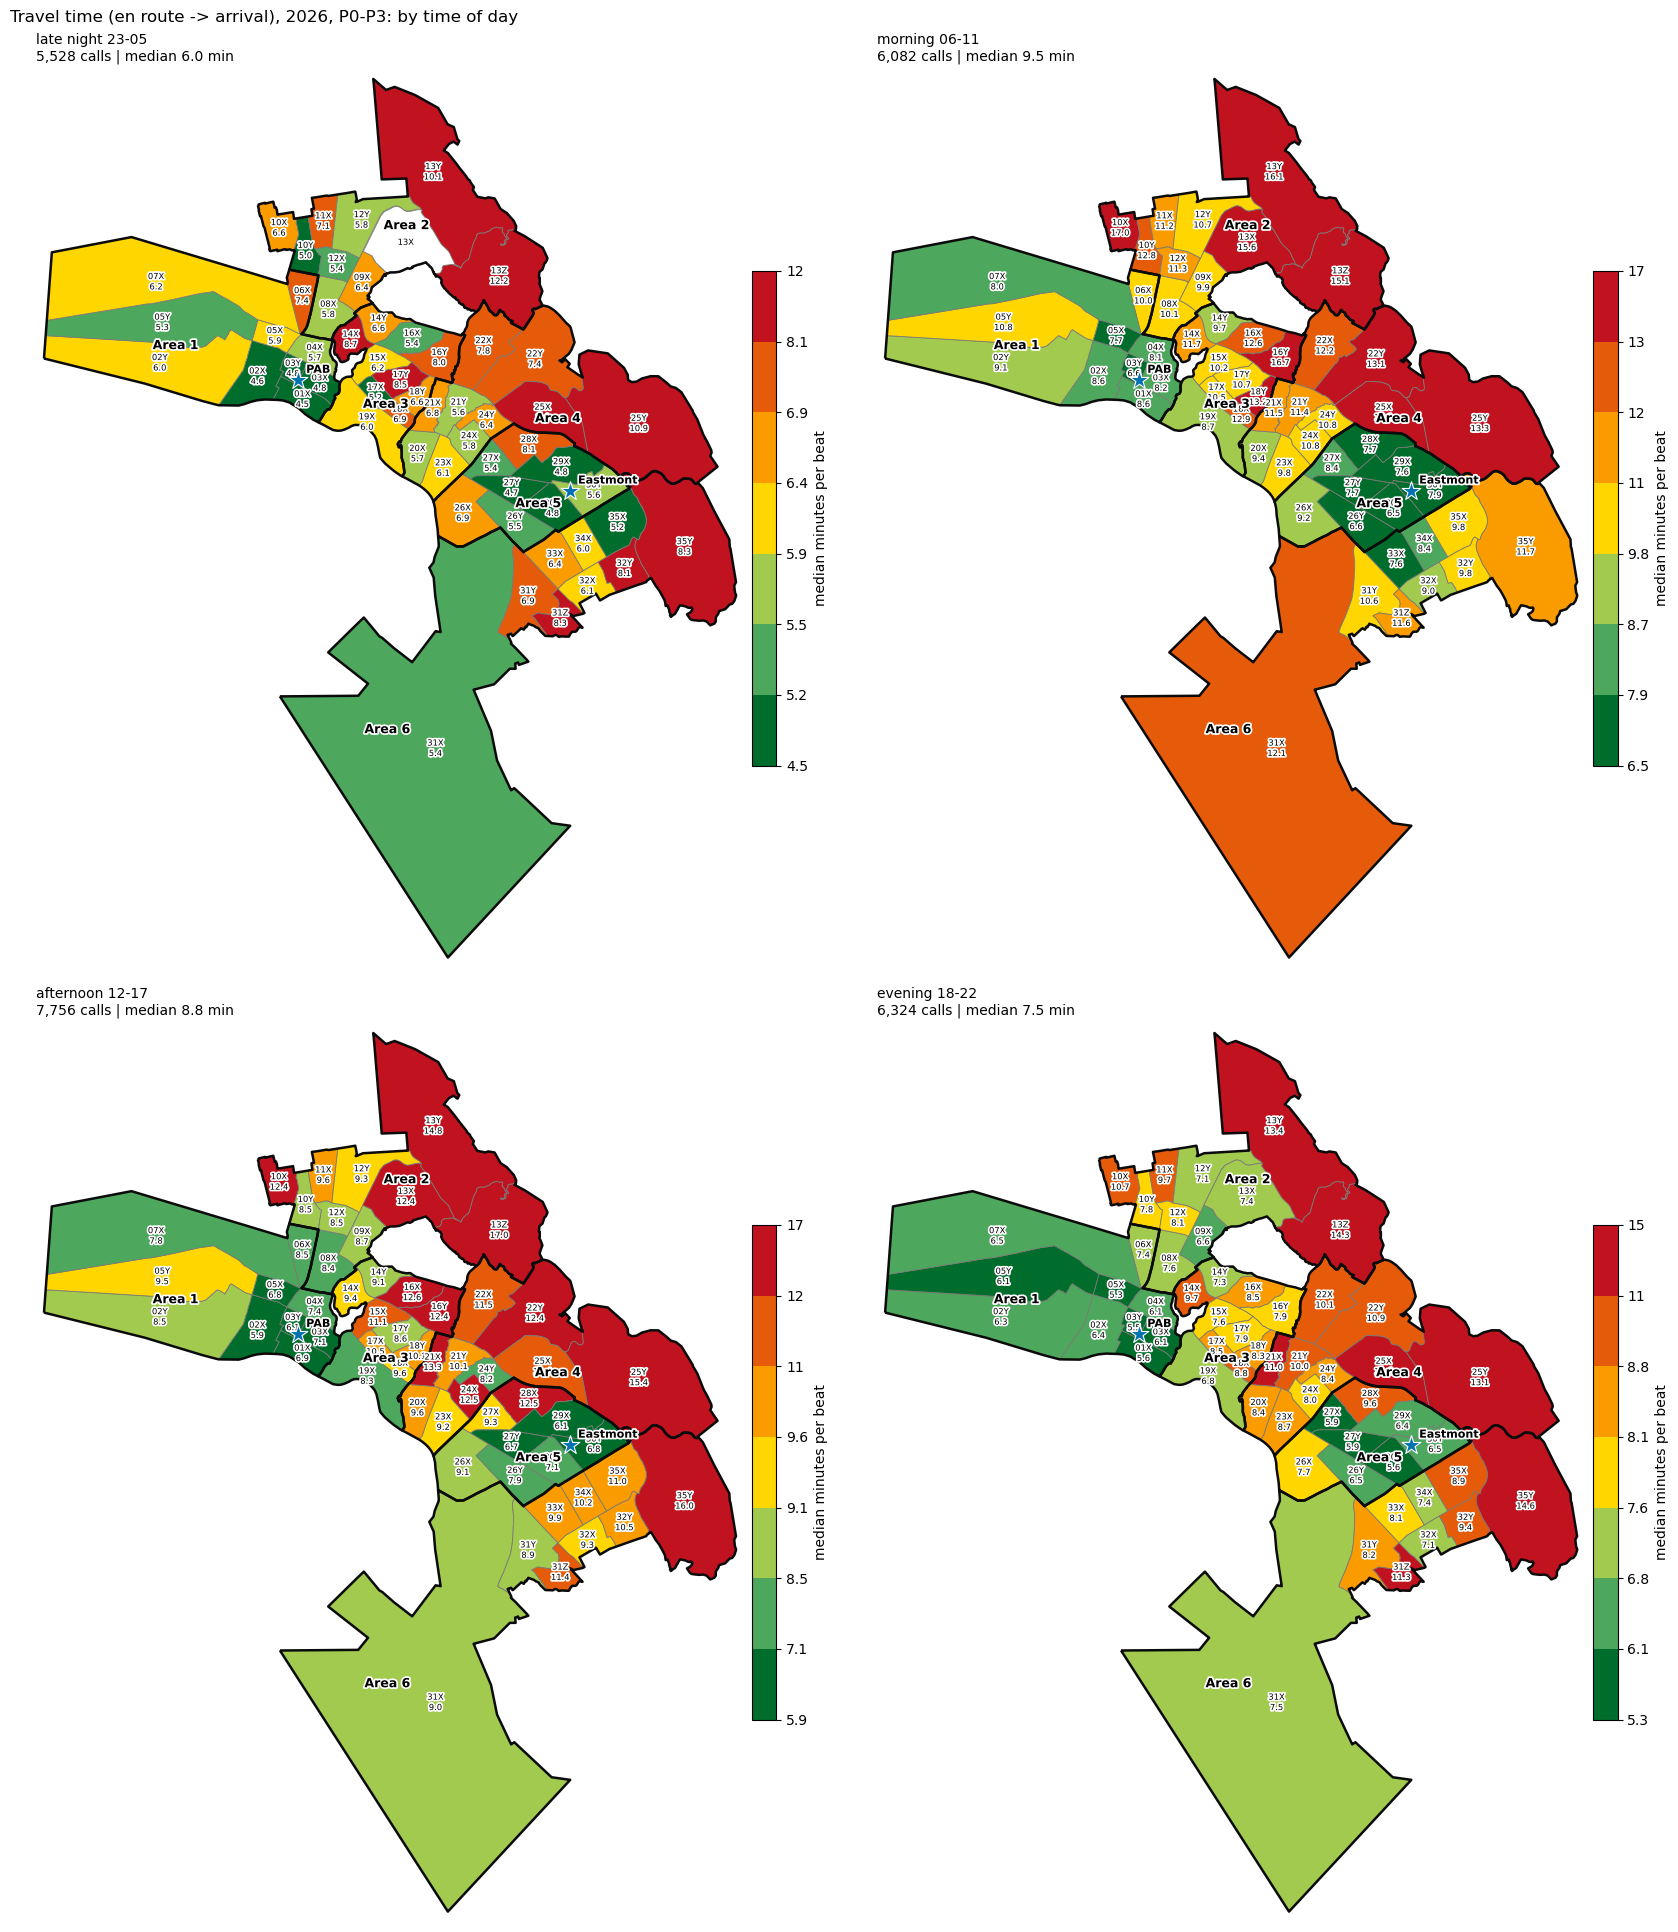

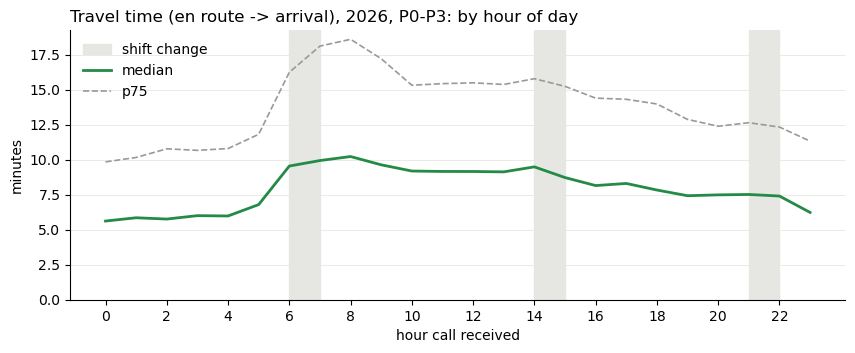

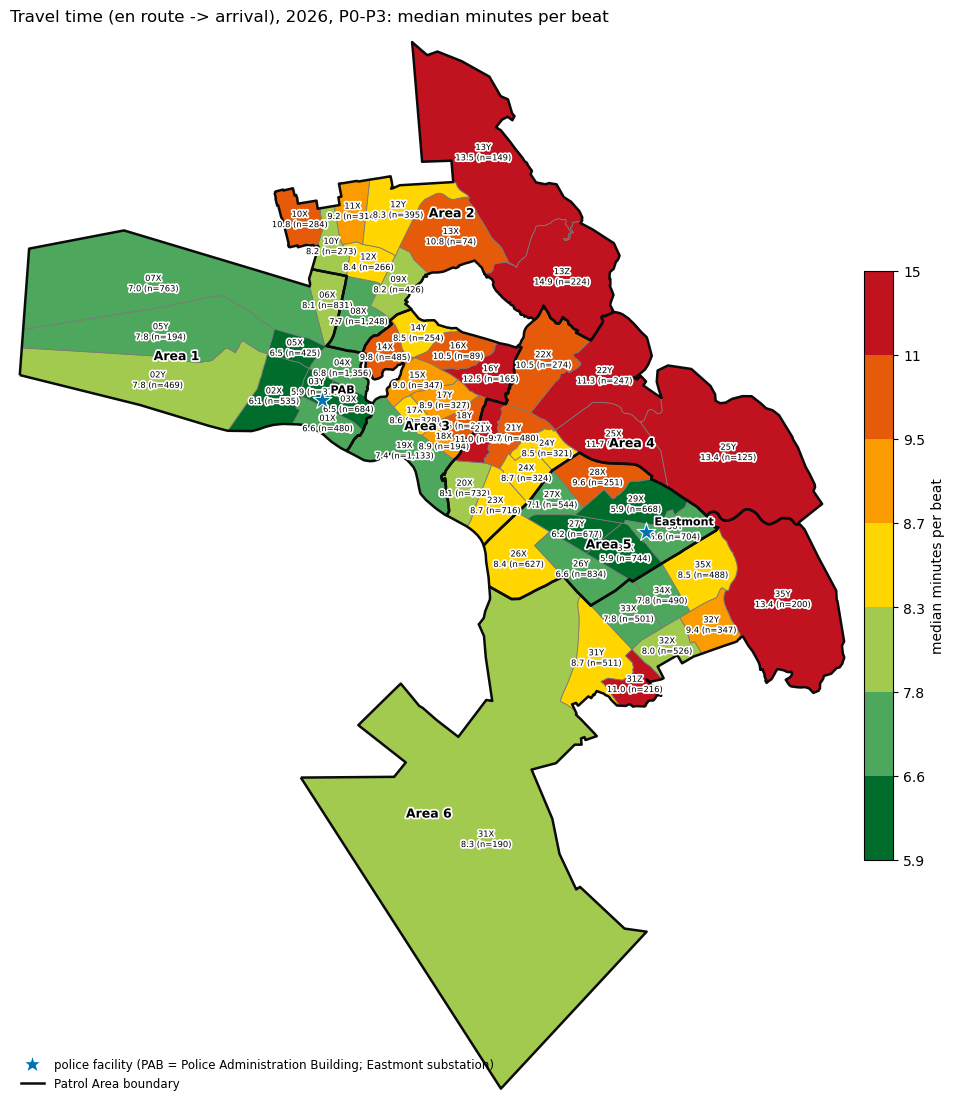

,n,median
beat,,
13Z,224,14.9
13Y,149,13.5
25Y,125,13.4
35Y,200,13.4
16Y,165,12.5
25X,411,11.7
22Y,247,11.3
21X,207,11.0
31Z,216,11.0


In [8]:
slice_maps(travel, "travel_min", "Travel time (en route -> arrival), 2026, P0-P3")

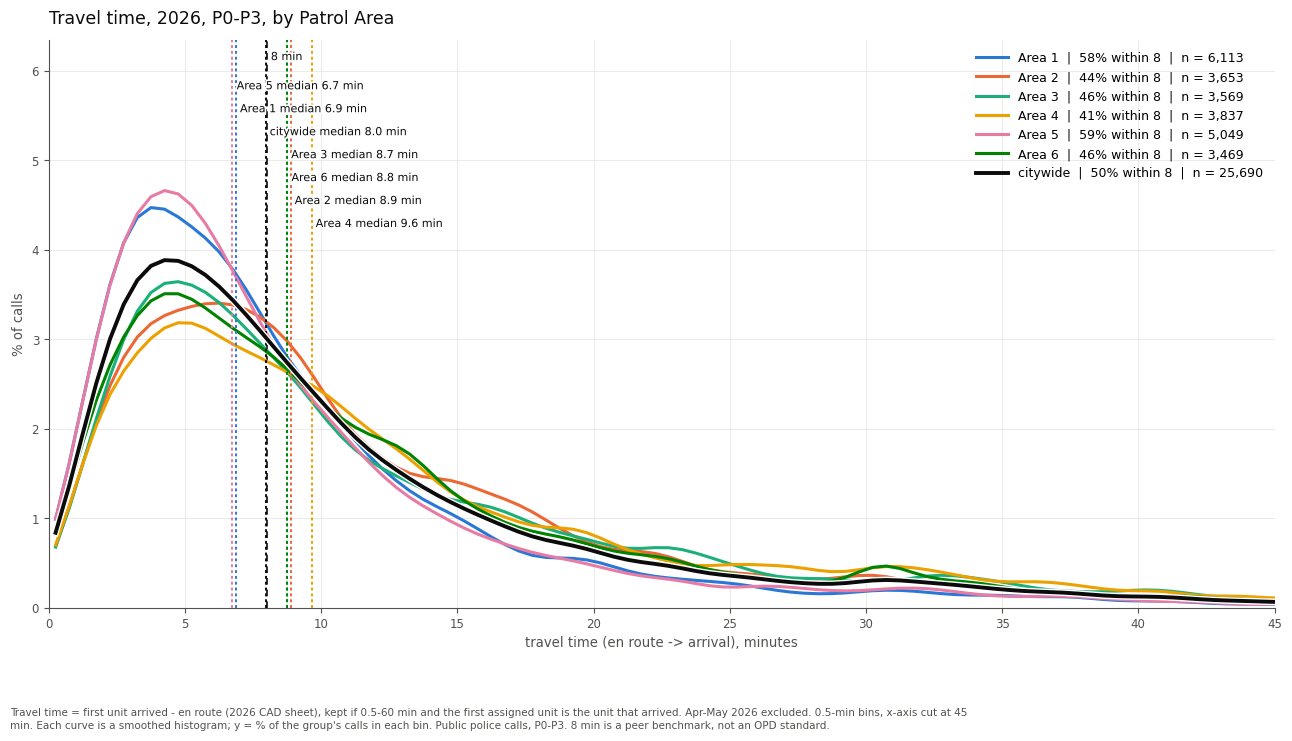

,n,median,within_8
area,,,
Area 1,6113,6.9,57.6
Area 2,3653,8.9,44.4
Area 3,3569,8.7,46.2
Area 4,3837,9.6,41.4
Area 5,5049,6.7,58.5
Area 6,3469,8.8,45.7


In [9]:
distribution(travel, "travel_min", "area", "Travel time, 2026, P0-P3", "travel time (en route -> arrival), minutes", TRAVEL_NOTE)

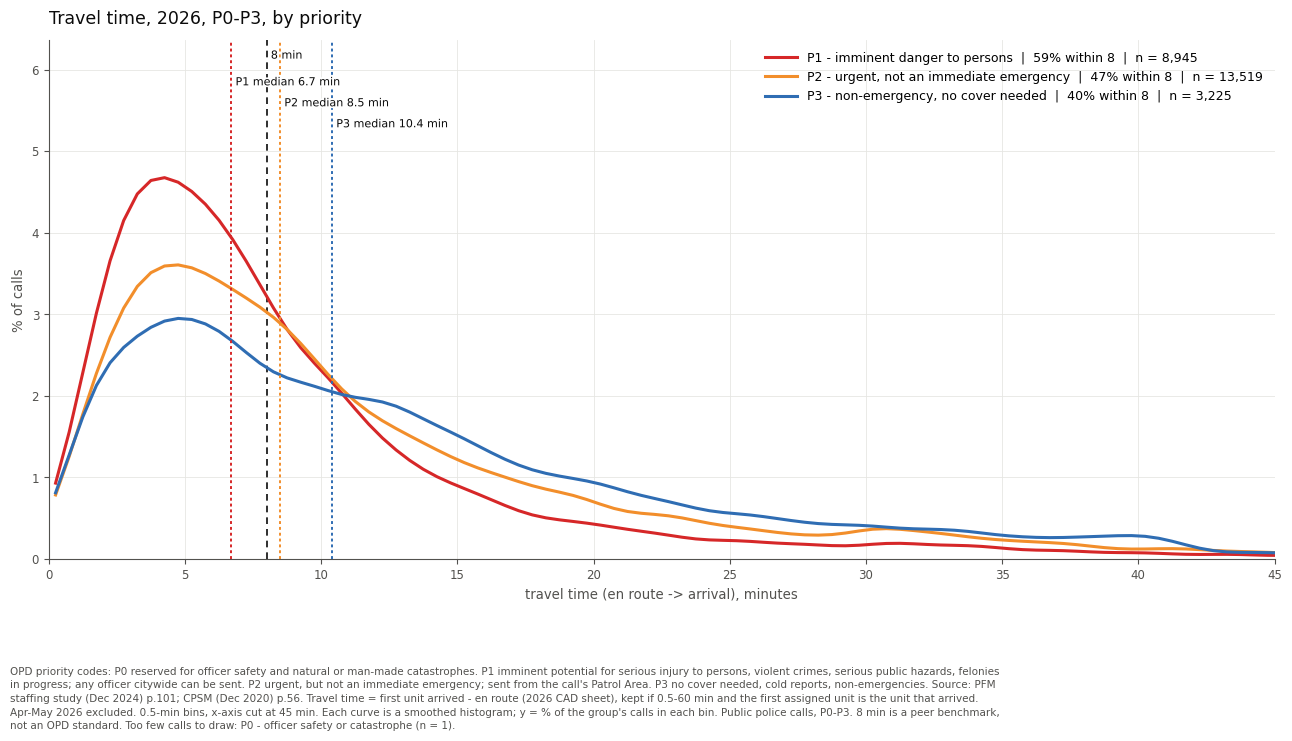

,n,median,within_8
priority,,,
P0 - officer safety or catastrophe,1,37.4,0.0
P1 - imminent danger to persons,8945,6.7,59.3
"P2 - urgent, not an immediate emergency",13519,8.5,46.9
"P3 - non-emergency, no cover needed",3225,10.4,39.7


In [10]:
distribution(travel, "travel_min", "priority", "Travel time, 2026, P0-P3", "travel time (en route -> arrival), minutes", TRAVEL_NOTE)

## Dispatch to arrival, 2021-2026

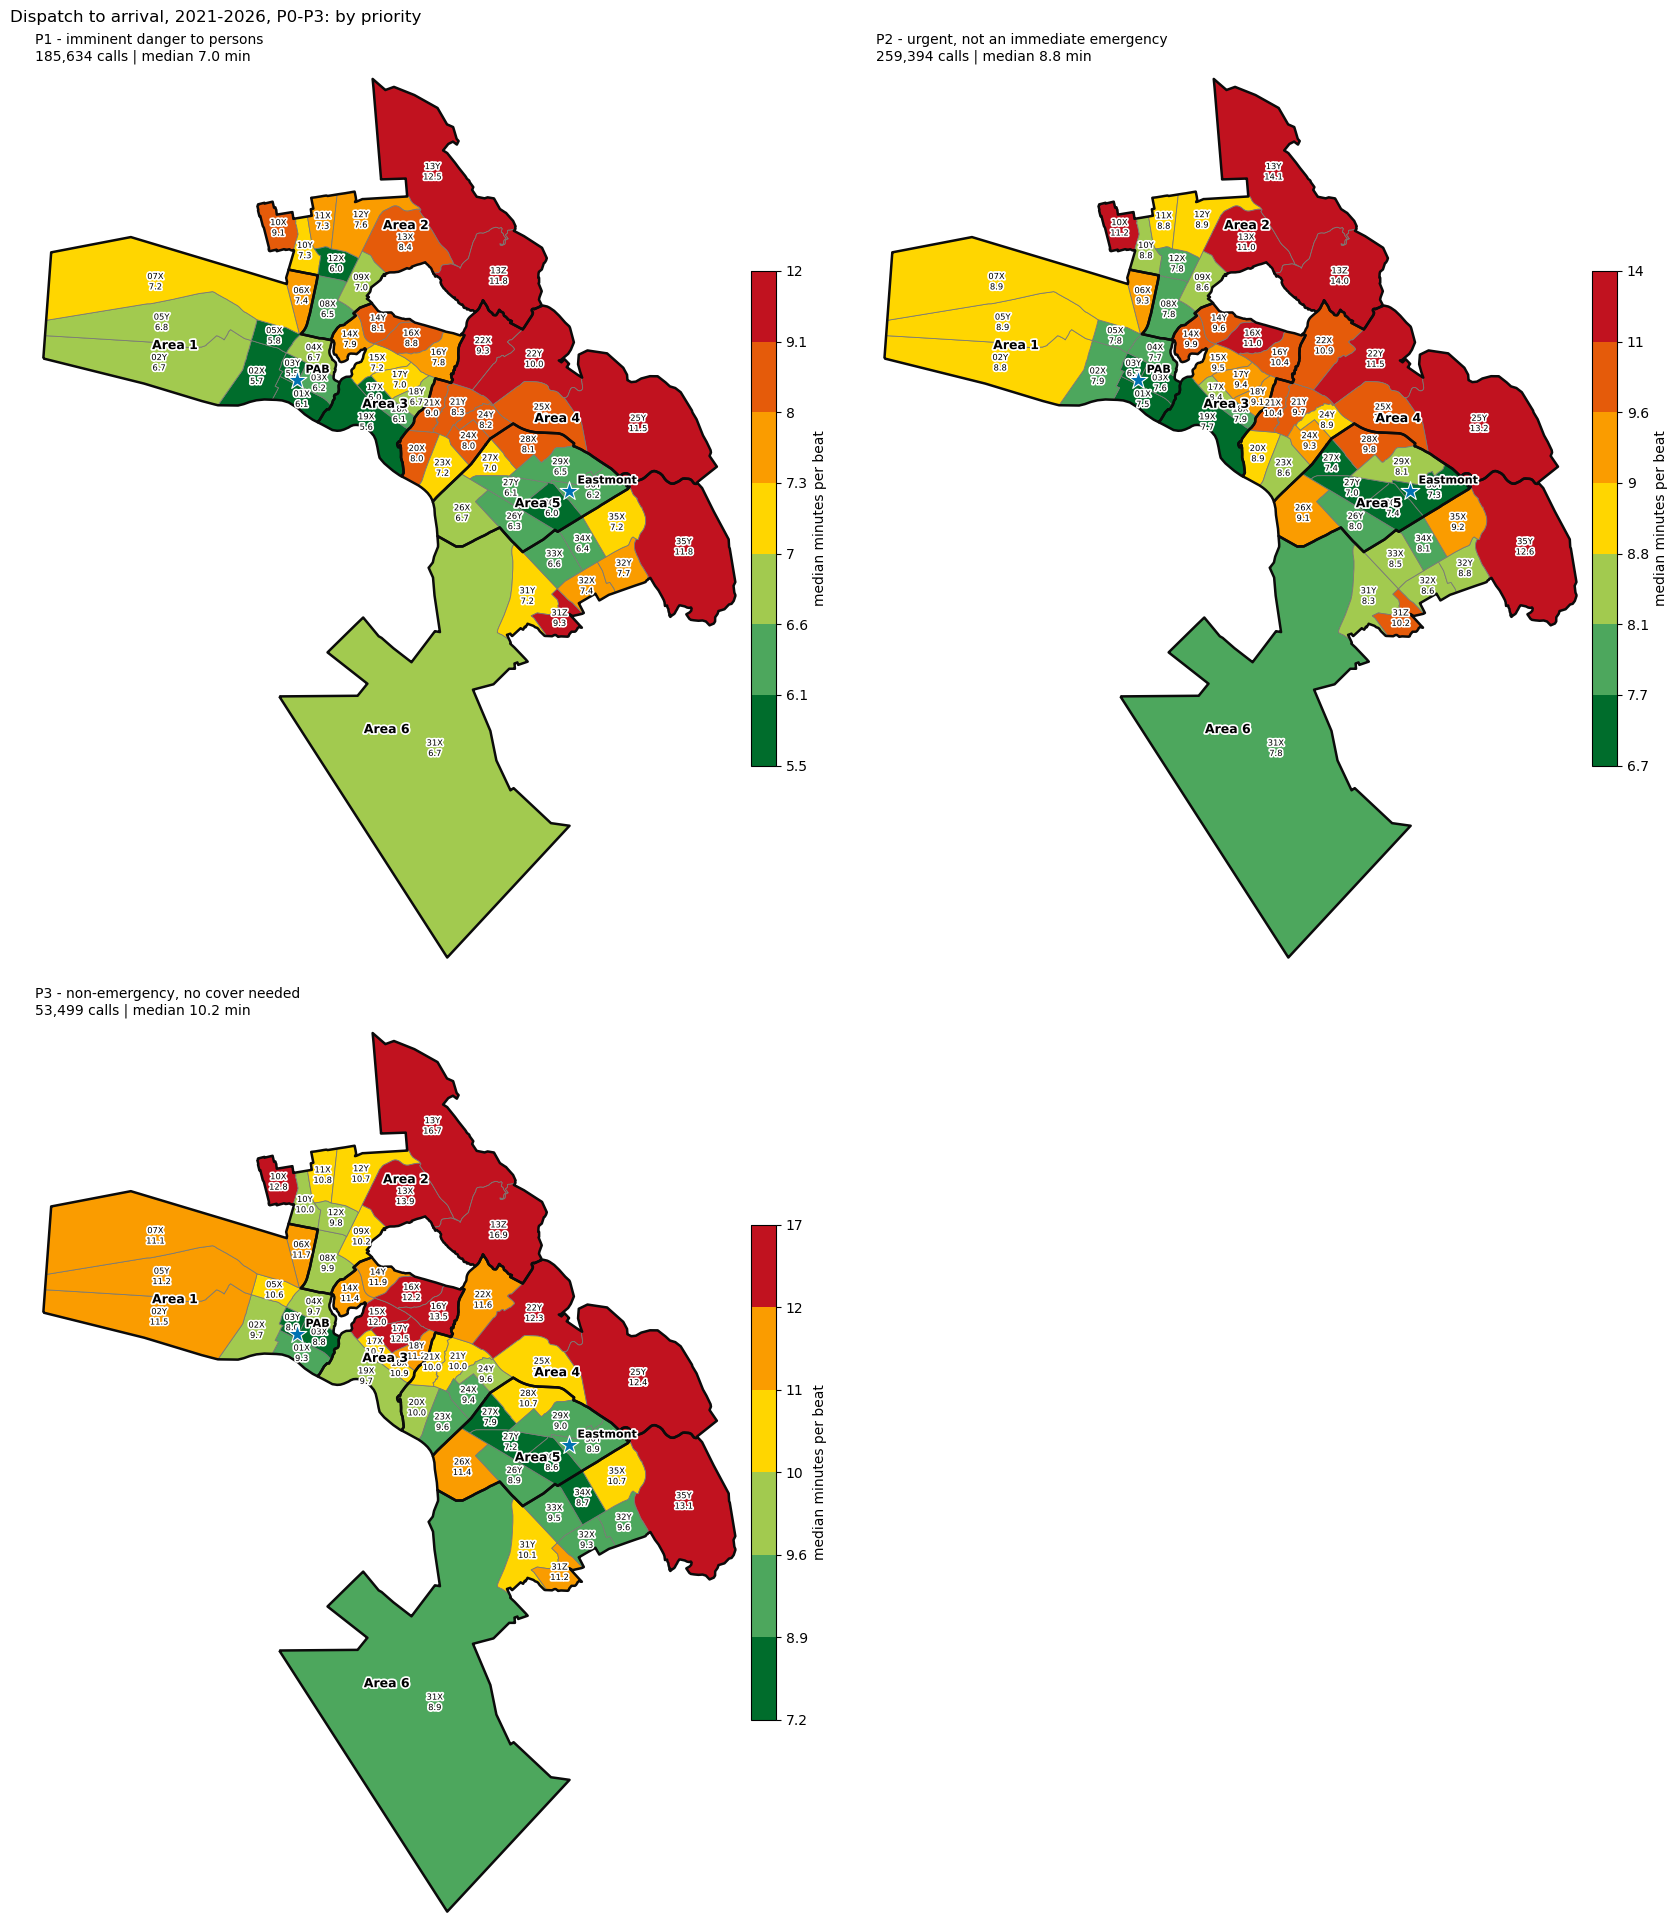

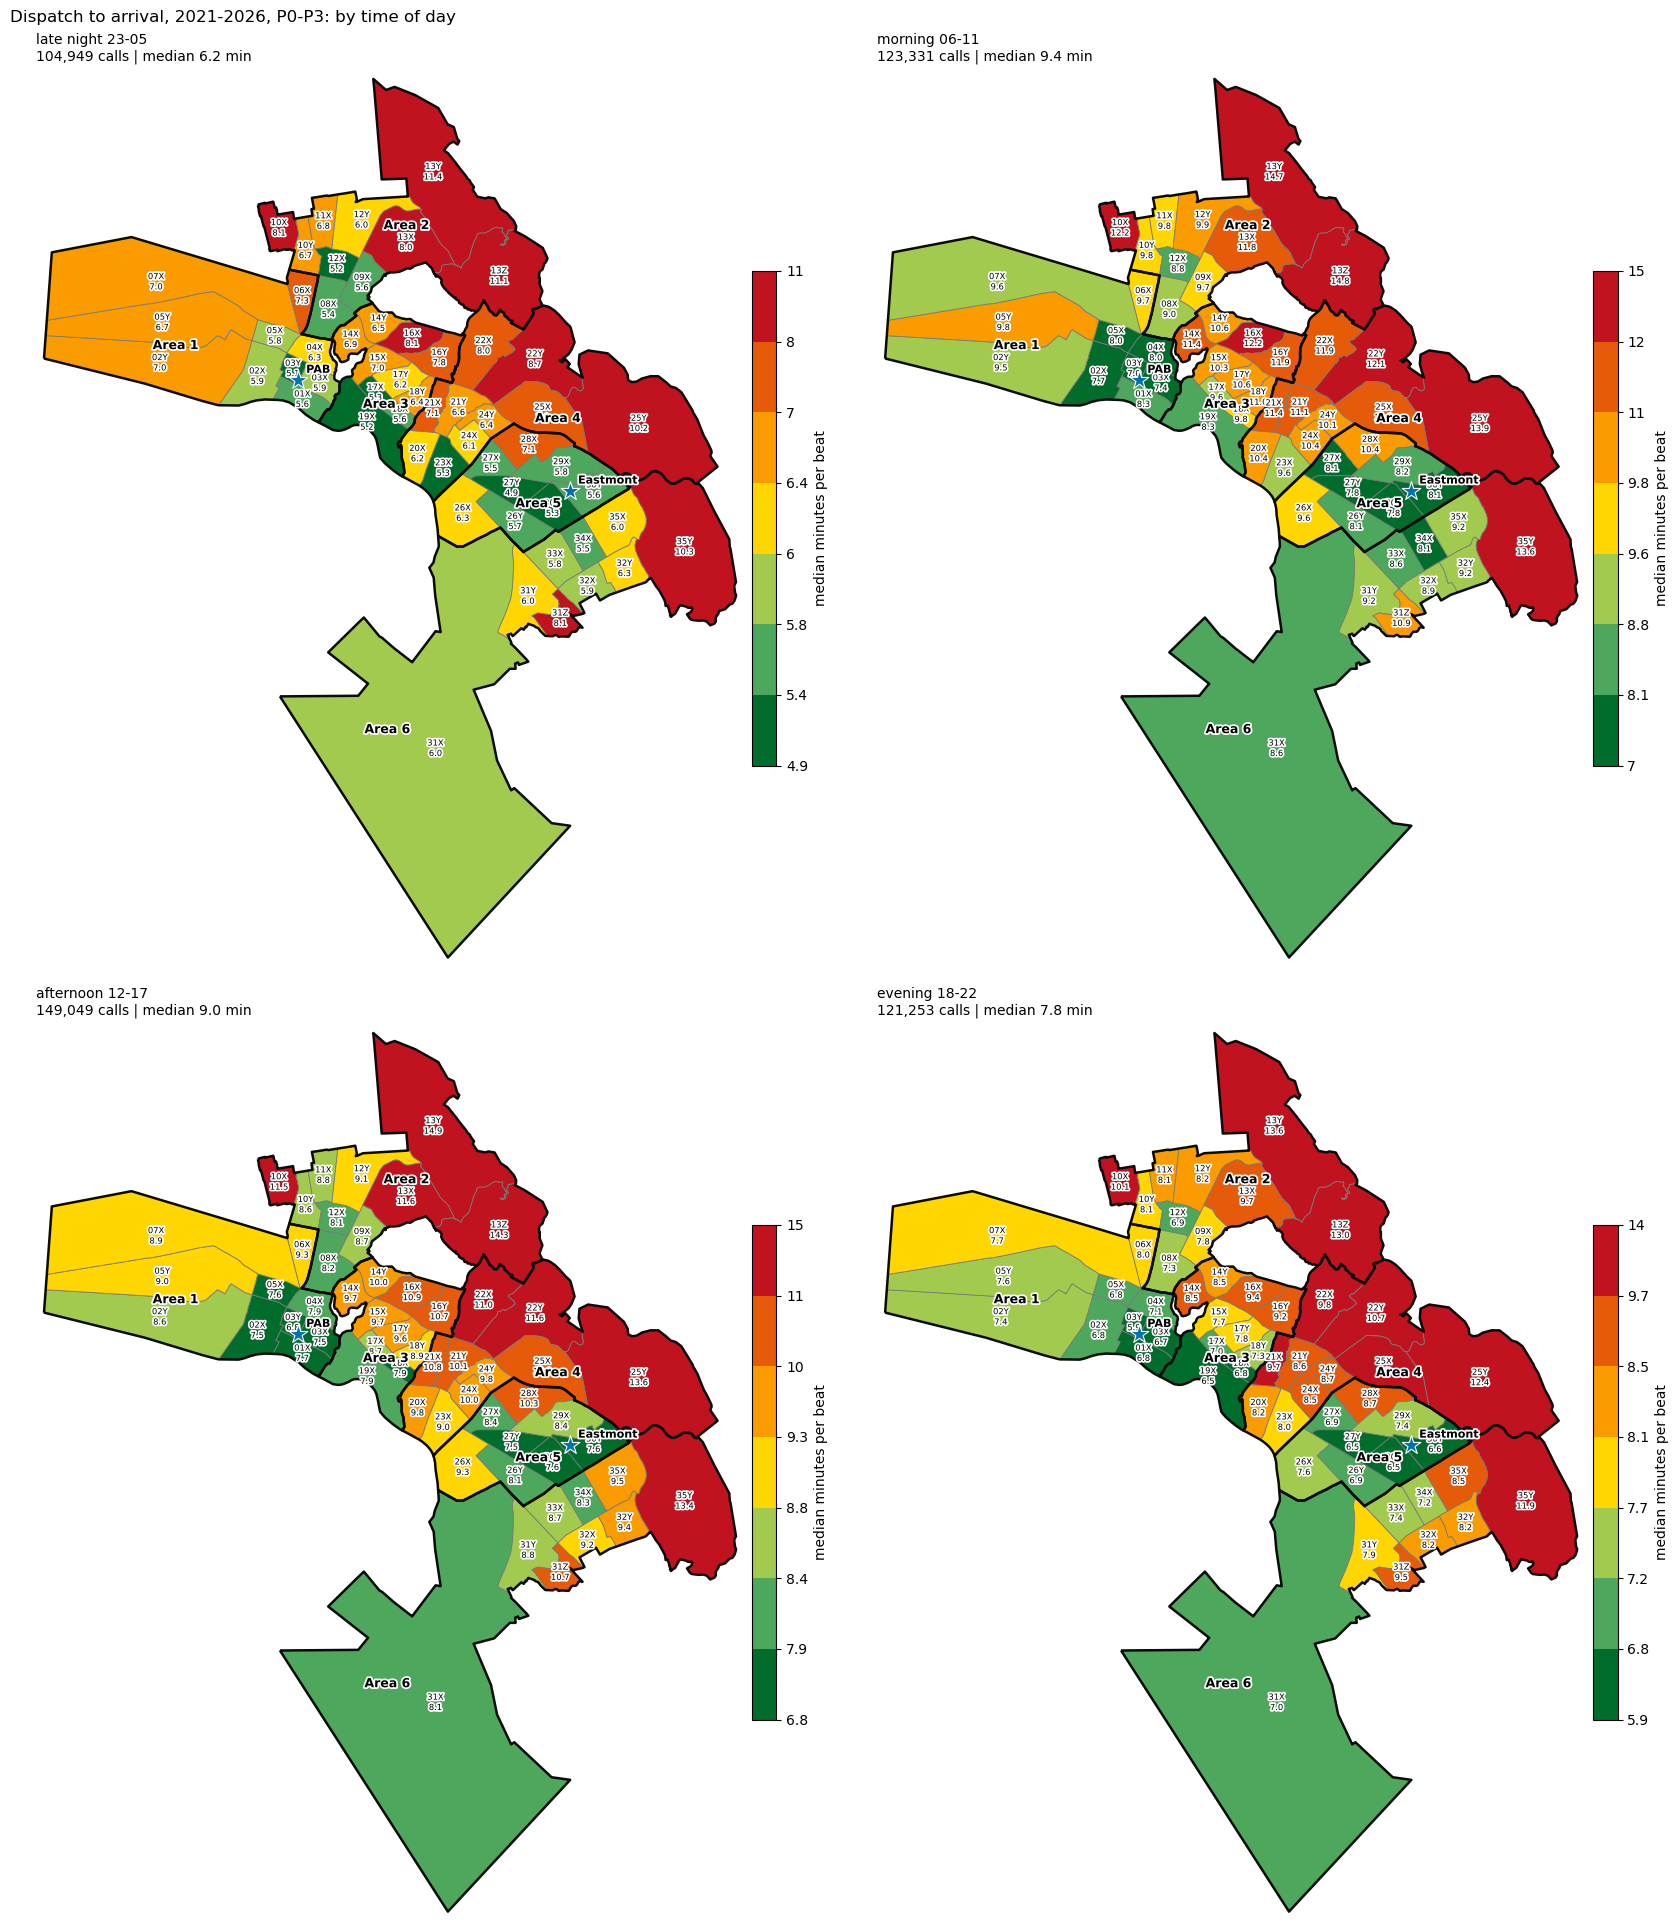

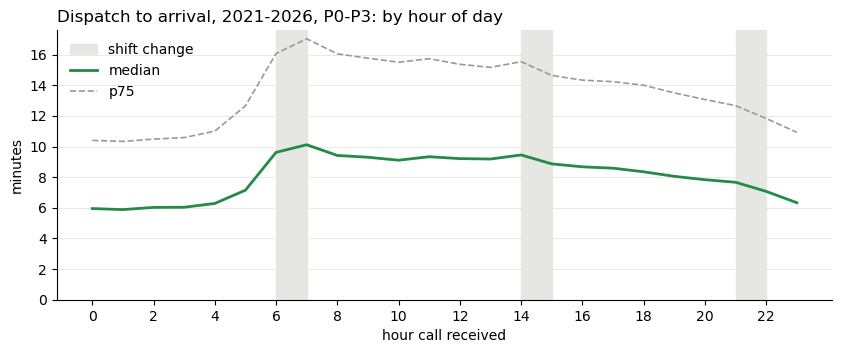

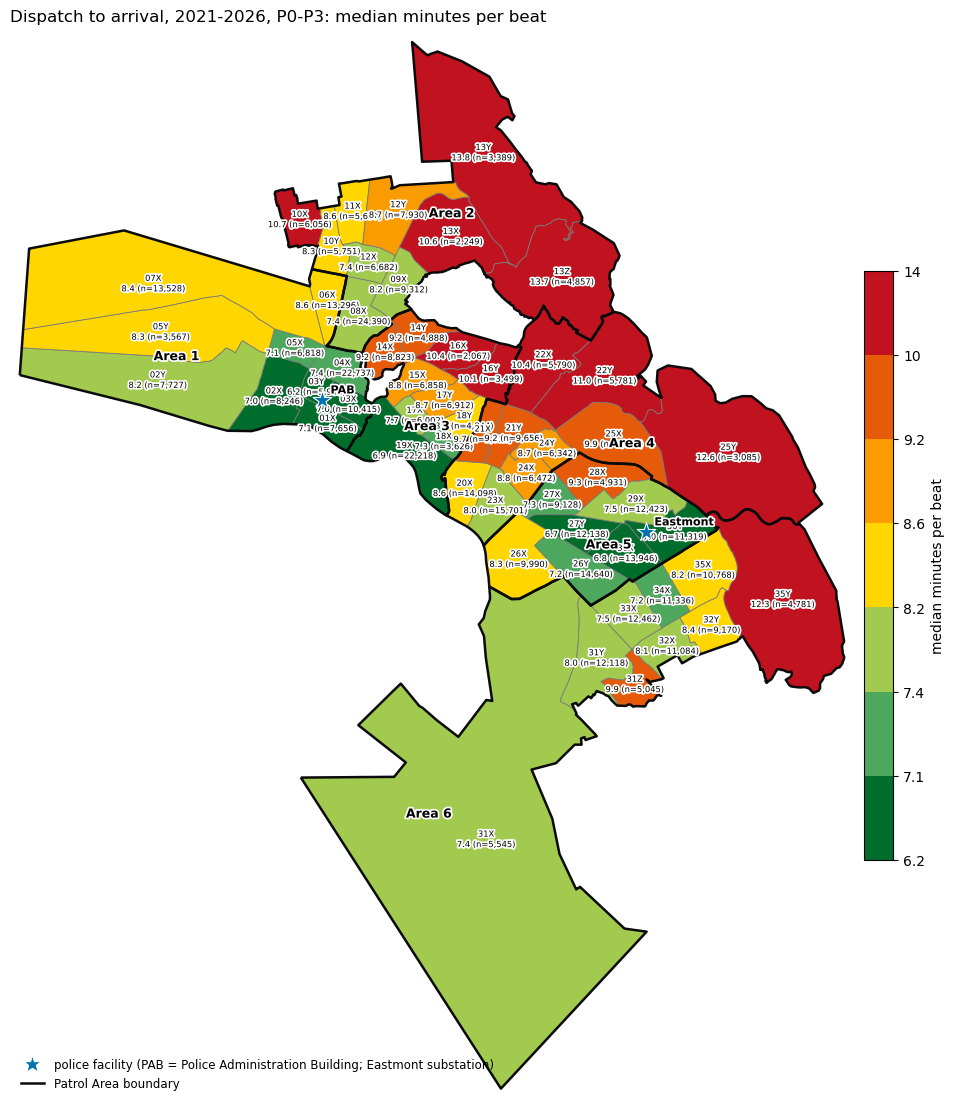

,n,median
beat,,
13Y,3389,13.8
13Z,4857,13.7
25Y,3085,12.6
35Y,4781,12.3
22Y,5781,11.0
10X,6056,10.7
13X,2249,10.6
22X,5790,10.4
16X,2067,10.4


In [11]:
slice_maps(calls, "dispatch_arrival_min", "Dispatch to arrival, 2021-2026, P0-P3")

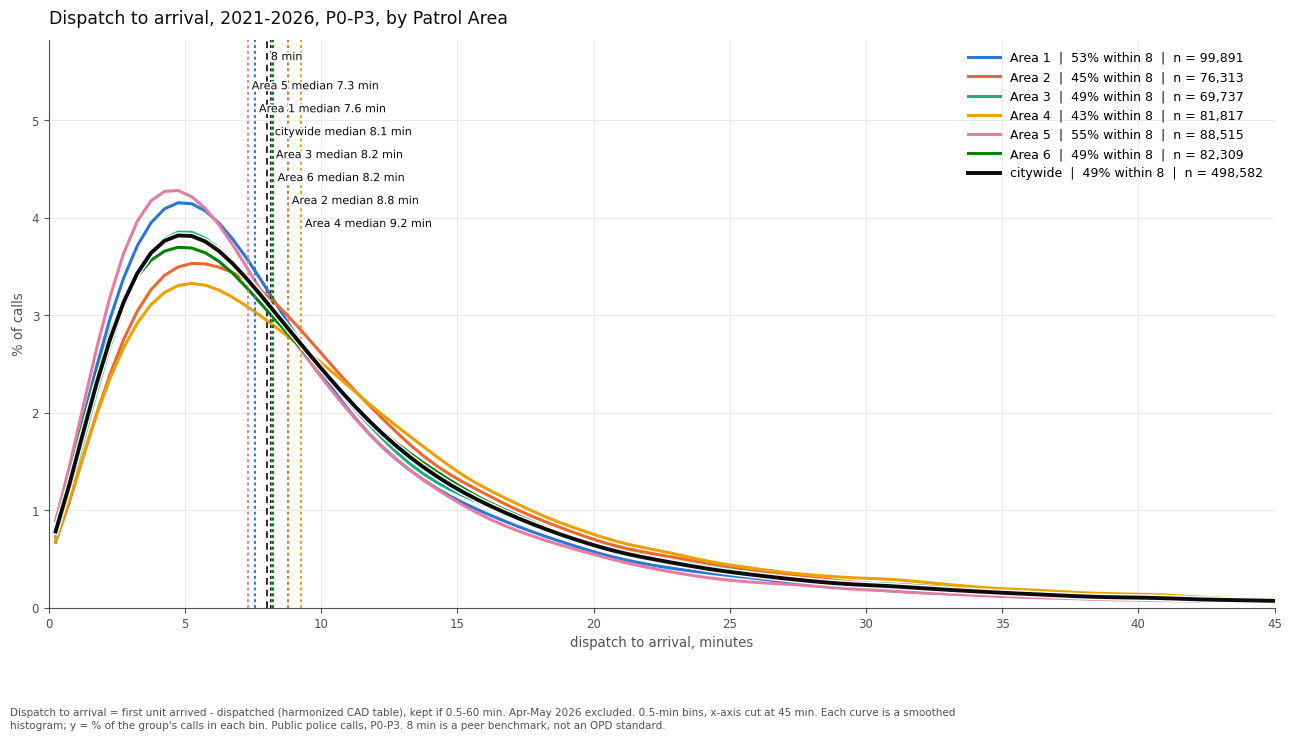

,n,median,within_8
area,,,
Area 1,99891,7.6,53.0
Area 2,76313,8.8,45.2
Area 3,69737,8.2,48.8
Area 4,81817,9.2,43.0
Area 5,88515,7.3,54.6
Area 6,82309,8.2,48.6


In [12]:
distribution(calls, "dispatch_arrival_min", "area", "Dispatch to arrival, 2021-2026, P0-P3", "dispatch to arrival, minutes", DISPATCH_NOTE)

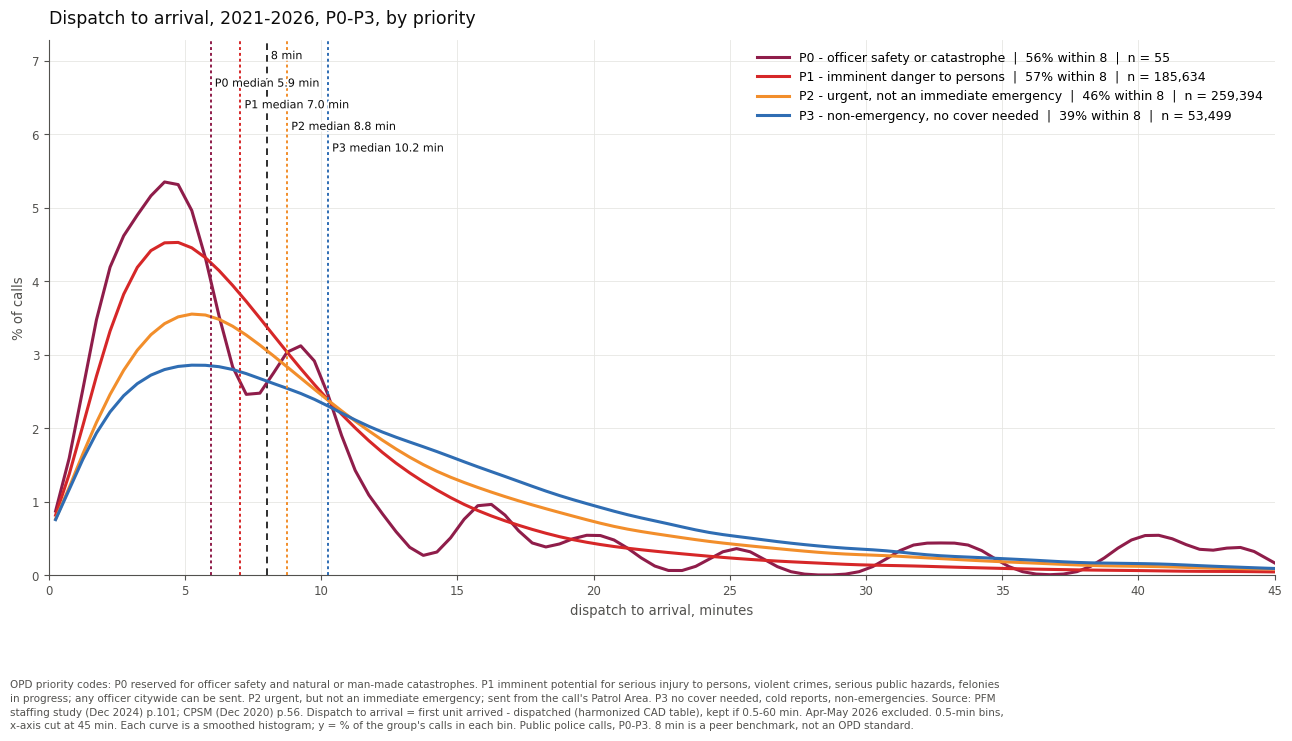

,n,median,within_8
priority,,,
P0 - officer safety or catastrophe,55,5.9,56.4
P1 - imminent danger to persons,185634,7.0,57.1
"P2 - urgent, not an immediate emergency",259394,8.8,45.6
"P3 - non-emergency, no cover needed",53499,10.2,38.7


In [13]:
distribution(calls, "dispatch_arrival_min", "priority", "Dispatch to arrival, 2021-2026, P0-P3", "dispatch to arrival, minutes", DISPATCH_NOTE)

## Response time (incident created -> arrival), 2021-2026

From the earliest CAD timestamp (incident created) to the first unit on scene: wait for dispatch plus dispatch to arrival. Kept when dispatch to arrival is 0.5-60 min and the total is at most 24 h. The time before the call taker creates the incident (ringing, answering, talking) is not in CAD.

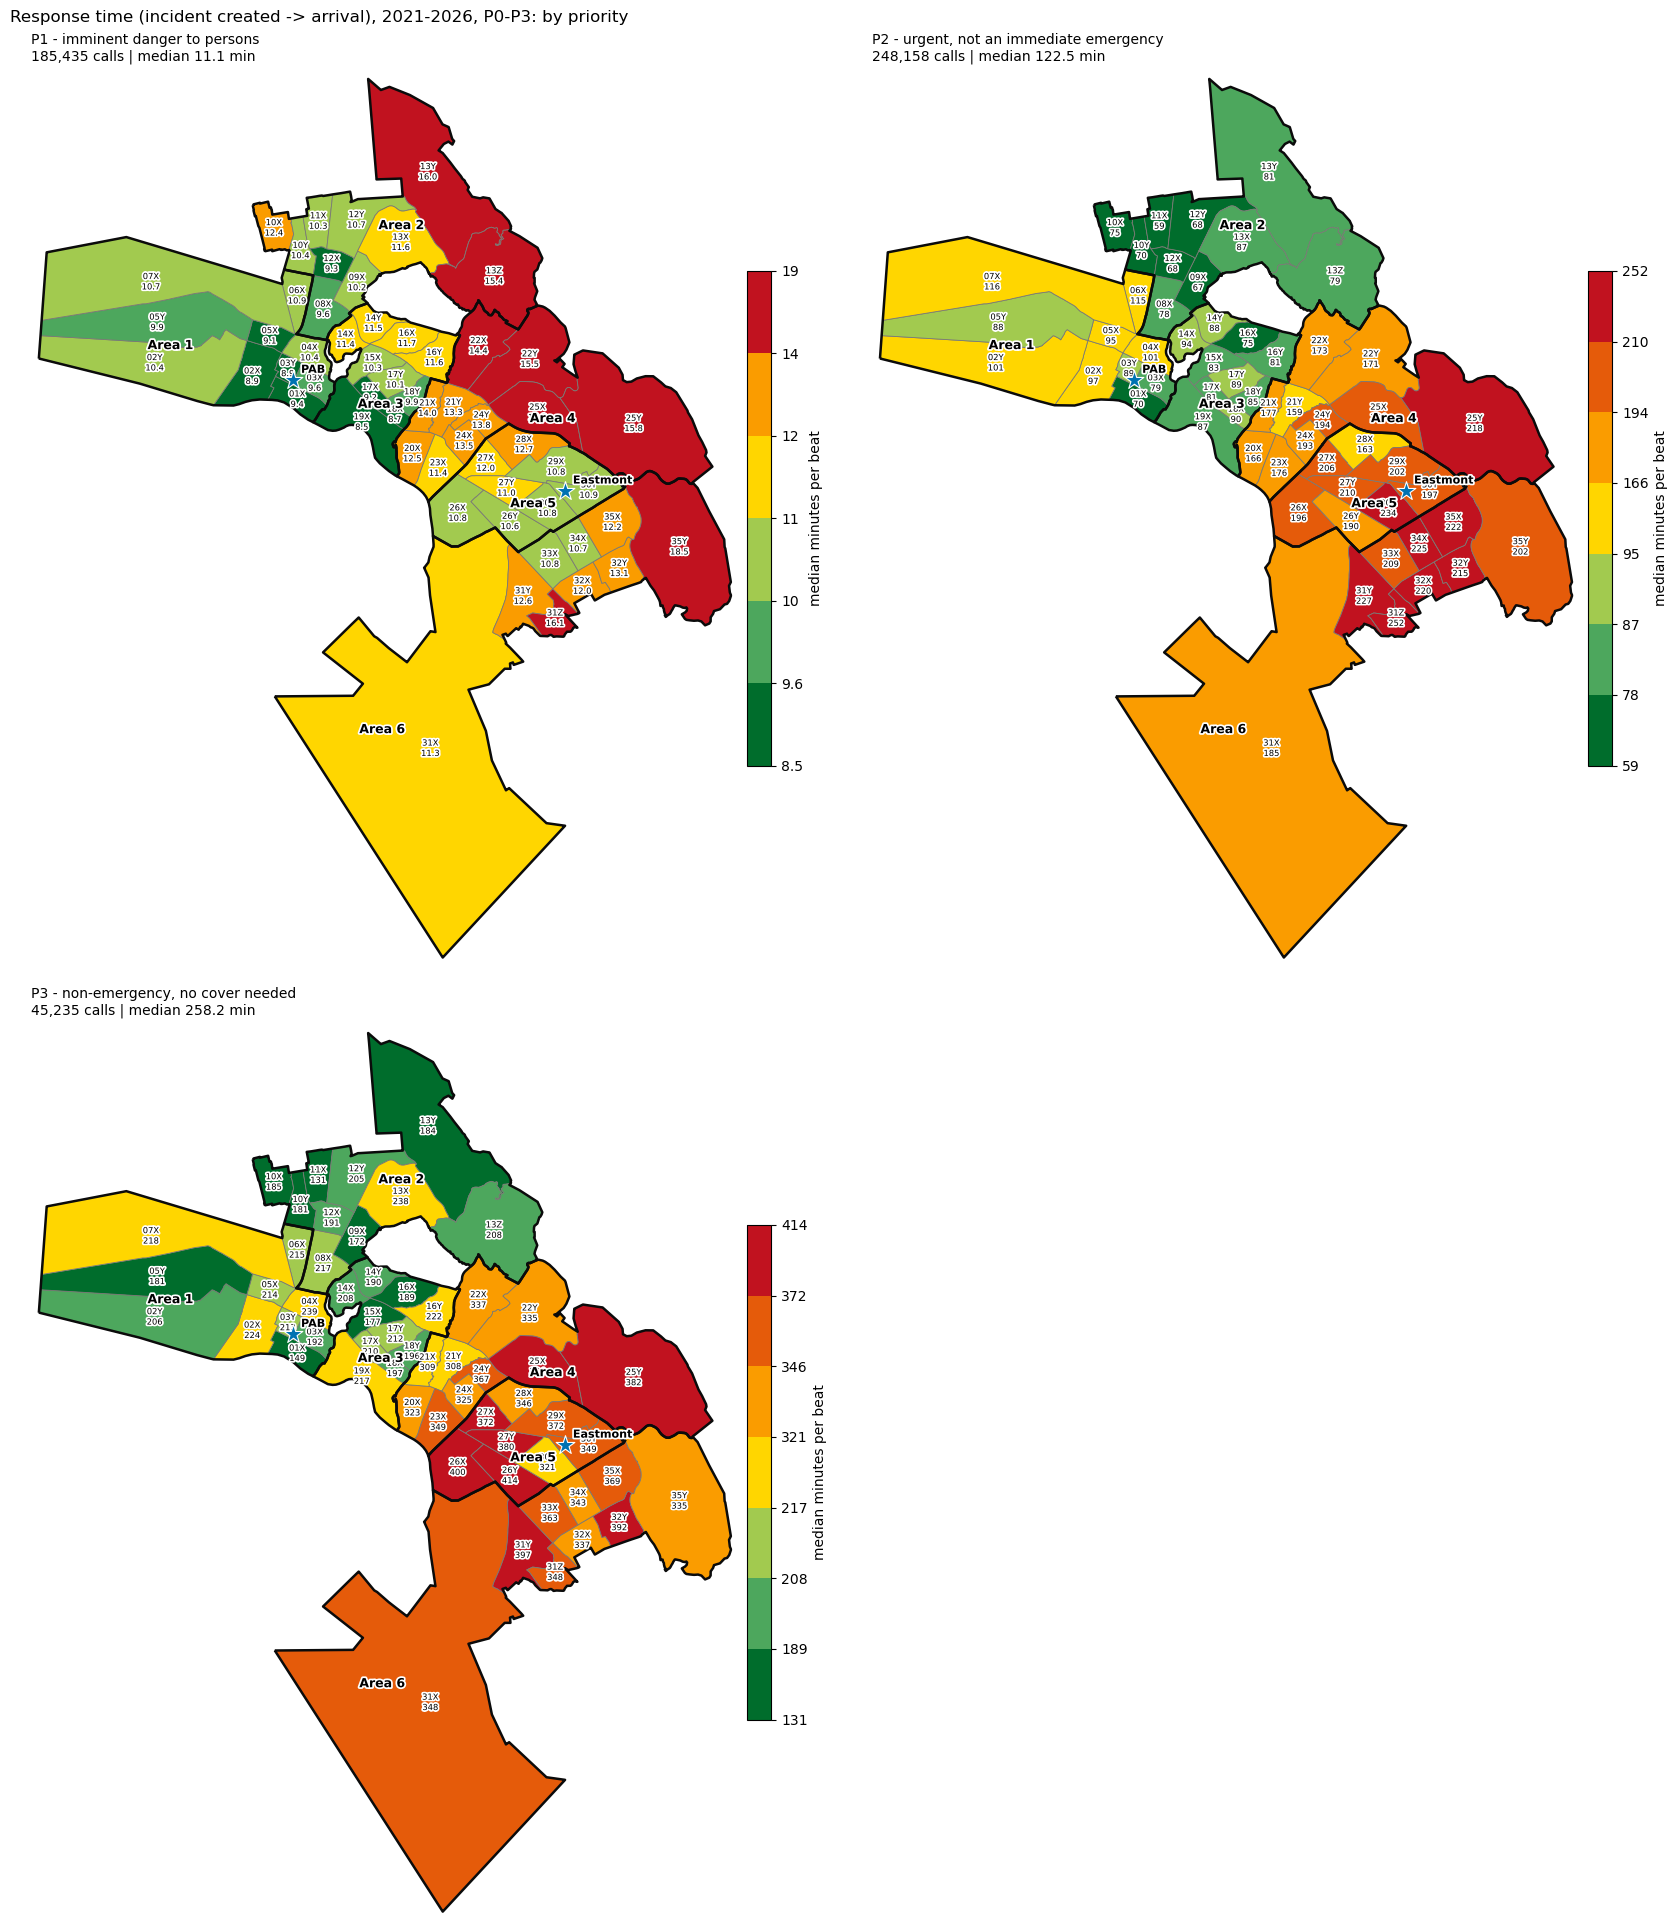

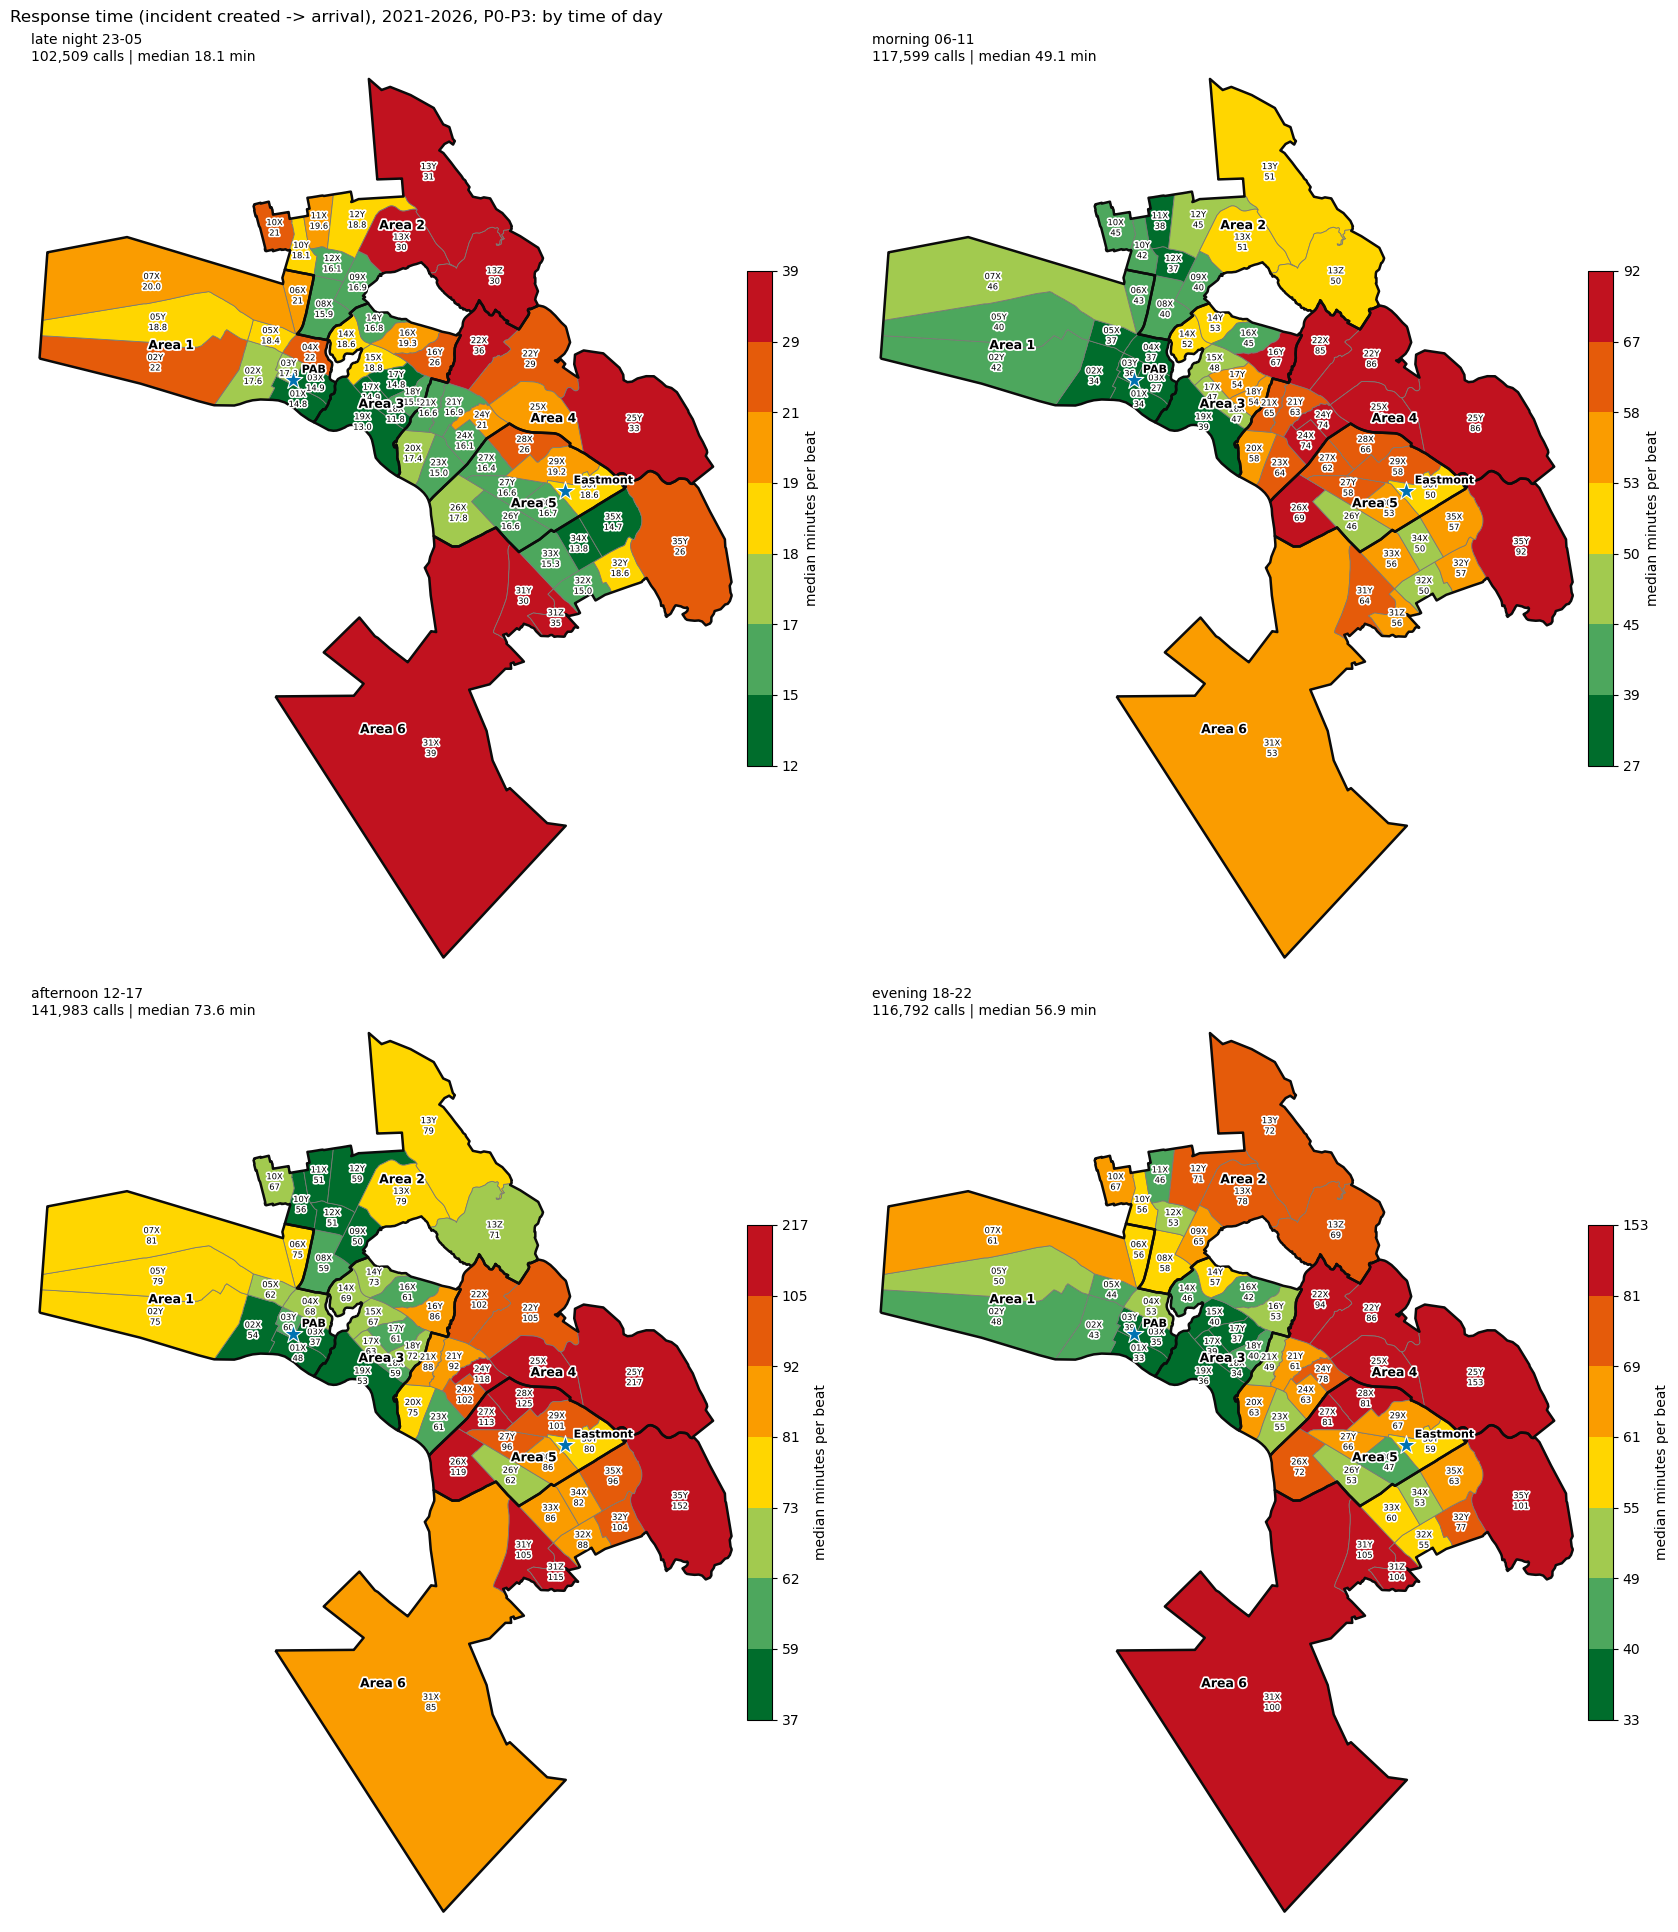

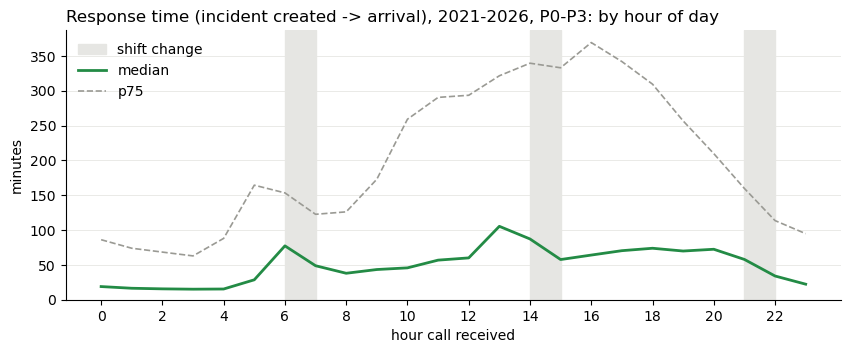

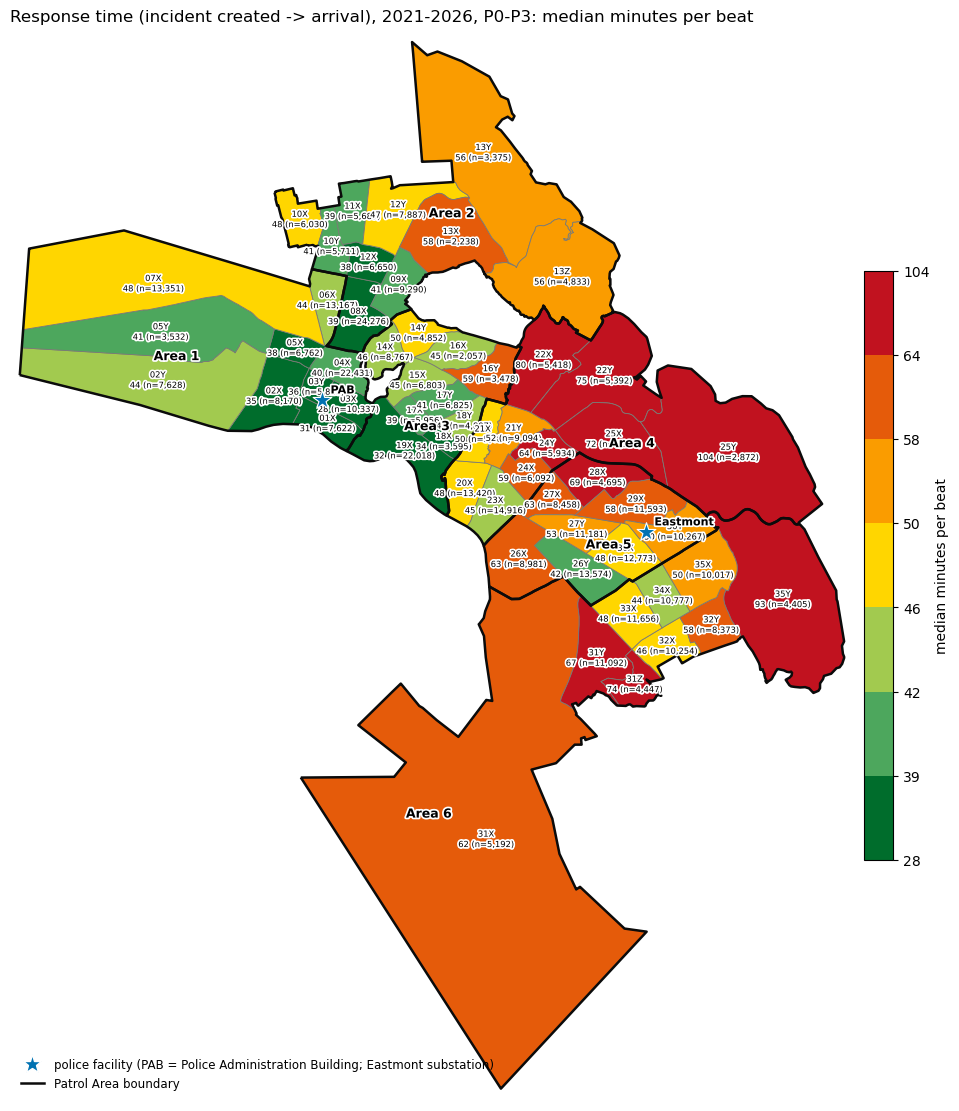

,n,median
beat,,
25Y,2872,104.2
35Y,4405,93.0
22X,5418,80.0
22Y,5392,75.2
31Z,4447,74.4
25X,8567,72.0
28X,4695,69.4
31Y,11092,66.7
24Y,5934,64.3


In [14]:
slice_maps(calls, "response_min", "Response time (incident created -> arrival), 2021-2026, P0-P3")

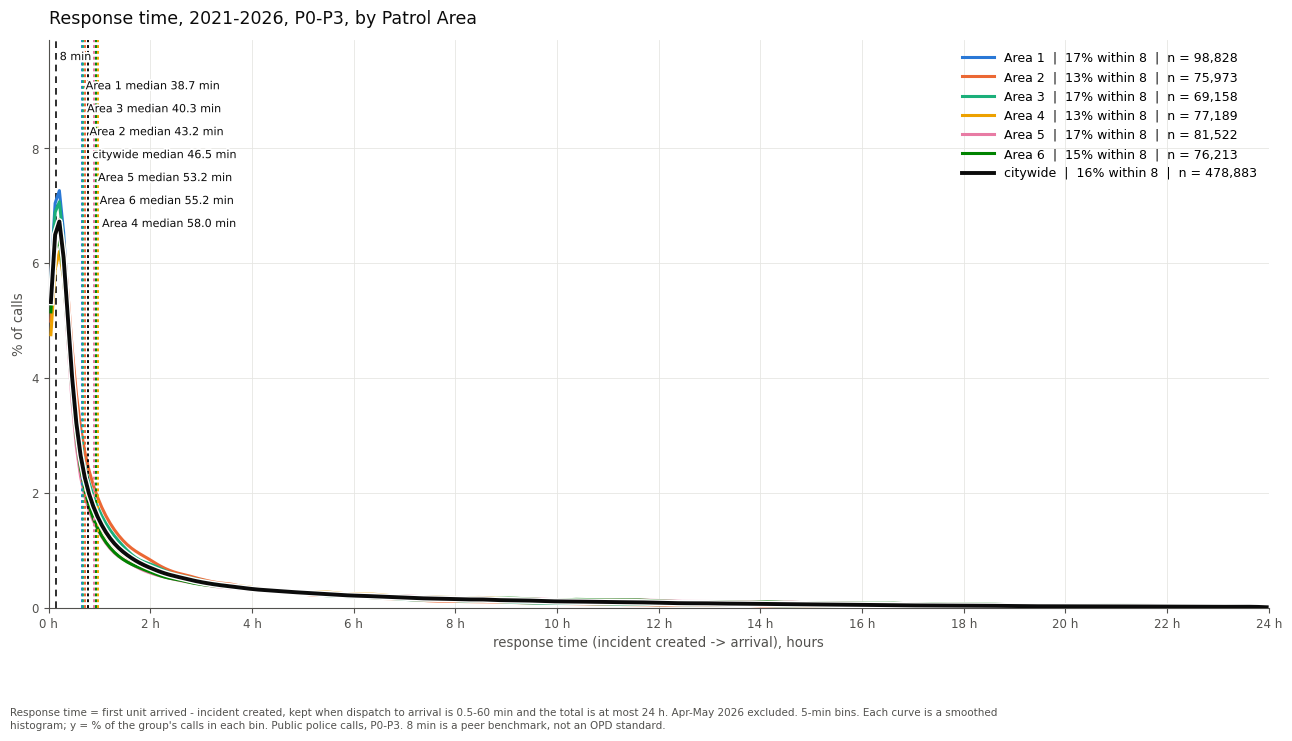

,n,median,within_8
area,,,
Area 1,98828,38.7,17.1
Area 2,75973,43.2,13.2
Area 3,69158,40.3,17.1
Area 4,77189,58.0,13.3
Area 5,81522,53.2,17.3
Area 6,76213,55.2,15.5


In [15]:
distribution(calls, "response_min", "area", "Response time, 2021-2026, P0-P3", "response time (incident created -> arrival), hours", RESPONSE_NOTE, max_min=1440, bin_min=5, xlim=1440)

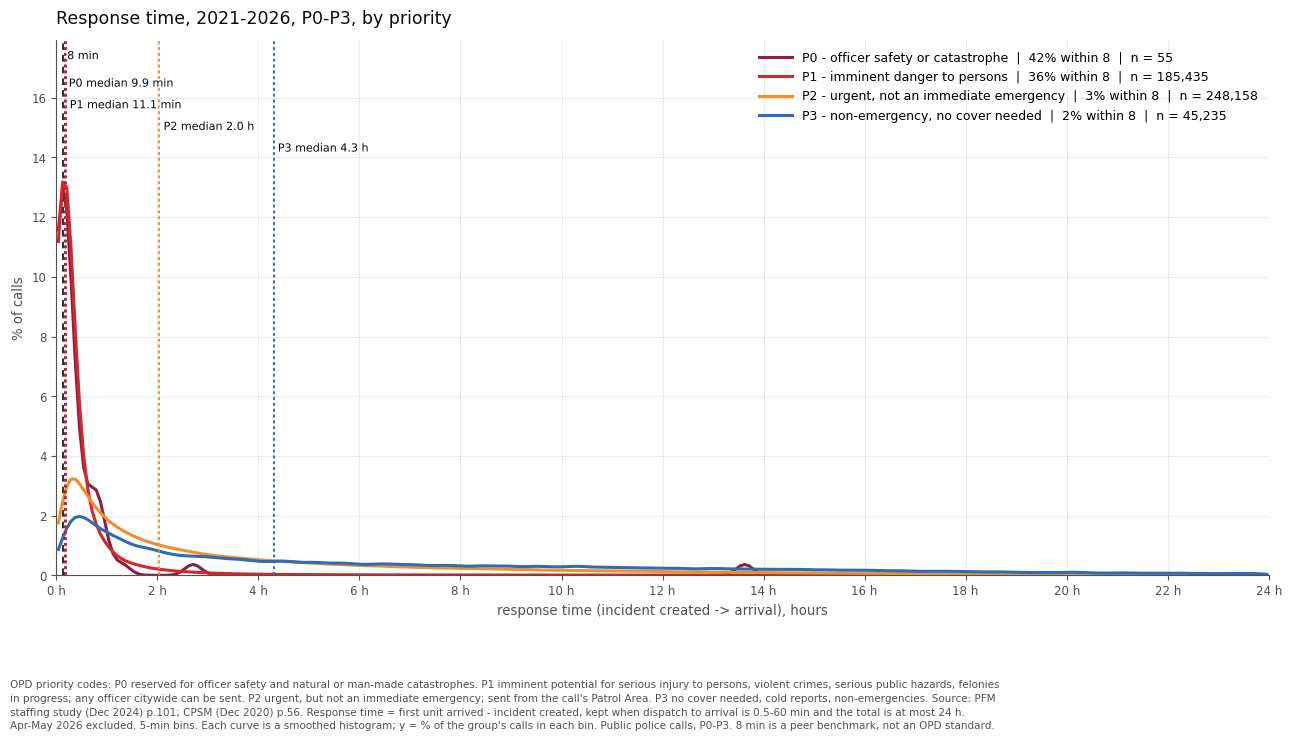

,n,median,within_8
priority,,,
P0 - officer safety or catastrophe,55,9.9,41.8
P1 - imminent danger to persons,185435,11.1,35.5
"P2 - urgent, not an immediate emergency",248158,122.5,3.3
"P3 - non-emergency, no cover needed",45235,258.2,1.6


In [16]:
distribution(calls, "response_min", "priority", "Response time, 2021-2026, P0-P3", "response time (incident created -> arrival), hours", RESPONSE_NOTE, max_min=1440, bin_min=5, xlim=1440)

In [ ]:
distribution(calls, "response_min", "area", "Response time, log scale, 2021-2026, P0-P3", "response time (incident created -> arrival), log scale", RESPONSE_NOTE.replace("5-min bins.", "Log-spaced x-axis (about 20 bins per decade), so y = % of calls per log-spaced bin."), max_min=1440, xlim=1440, log=True)